
# Module 5 · Lab 5.4 — RAG Evaluation: Own Your Metrics
## Measure retrieval and generation with graders you wrote, can read, and can defend

---

### Lab overview

Lab 5.3 built the three-layer evaluation hierarchy and filled in layers 1 and 3. **This lab is
layer 2** — the one that decides whether a RAG system is actually working.

It evaluates a system you have already built: **PROJECT 1**, the Meridian Wealth Partners
financial analyst from Lab 2.2, running over its real 174-page policy corpus. Not a toy inline
corpus invented for the occasion. An evaluation lab that evaluates a toy is a demo.

| Part | You will build |
|---|---|
| **A · The system under test** | PROJECT 1's retrieval pipeline, rebuilt with the **generation step it never had** |
| **B · Retrieval metrics** | `recall@k`, `precision@k`, `MRR`, `nDCG@k` — implemented, not imported |
| **C · Generation metrics** | **Faithfulness** by claim decomposition, and **answer relevancy** — with prompts you can read and edit |
| **D · Grader calibration** | Measure your own graders against human labels. **This is the part that matters.** |

### Learning objectives
1. Build a **golden dataset** with written-down relevance criteria — binary for recall, graded 0–3 for nDCG
2. Implement the four retrieval metrics from their definitions, and know what each one catches that the others miss
3. Implement **faithfulness as claim decomposition + per-claim entailment**, which is all it has ever been
4. Judge **cross-family** — the system under test runs on OpenAI, so the grader does not
5. **Calibrate your graders against human labels** and act on the disagreement
6. Run a real improvement cycle: change one thing, re-measure, and let the numbers decide

### Prerequisites
- `OPENAI_API_KEY` and `ANTHROPIC_API_KEY` · Colab recommended
- Labs 2.2 (PROJECT 1) and 5.3 (the eval hierarchy)
- The `Lab_5.4 Files/docs/` folder next to this notebook — the same five policy PDFs PROJECT 1 uses

> **Why this lab implements its own metrics instead of calling a framework.** RAGAS moved
> 0.2 → 0.3 → 0.4 inside a year, deprecated `evaluate()`, relocated its metrics, and migrated
> only about 43% of them — and its recommended metrics do not currently work with its
> recommended runner. But churn is the smaller reason. The bigger one: a lab called *RAG
> Evaluation* in which you write four lines and receive four numbers teaches you a library, not
> evaluation. Section 15 revisits this honestly, including what going custom genuinely costs you.


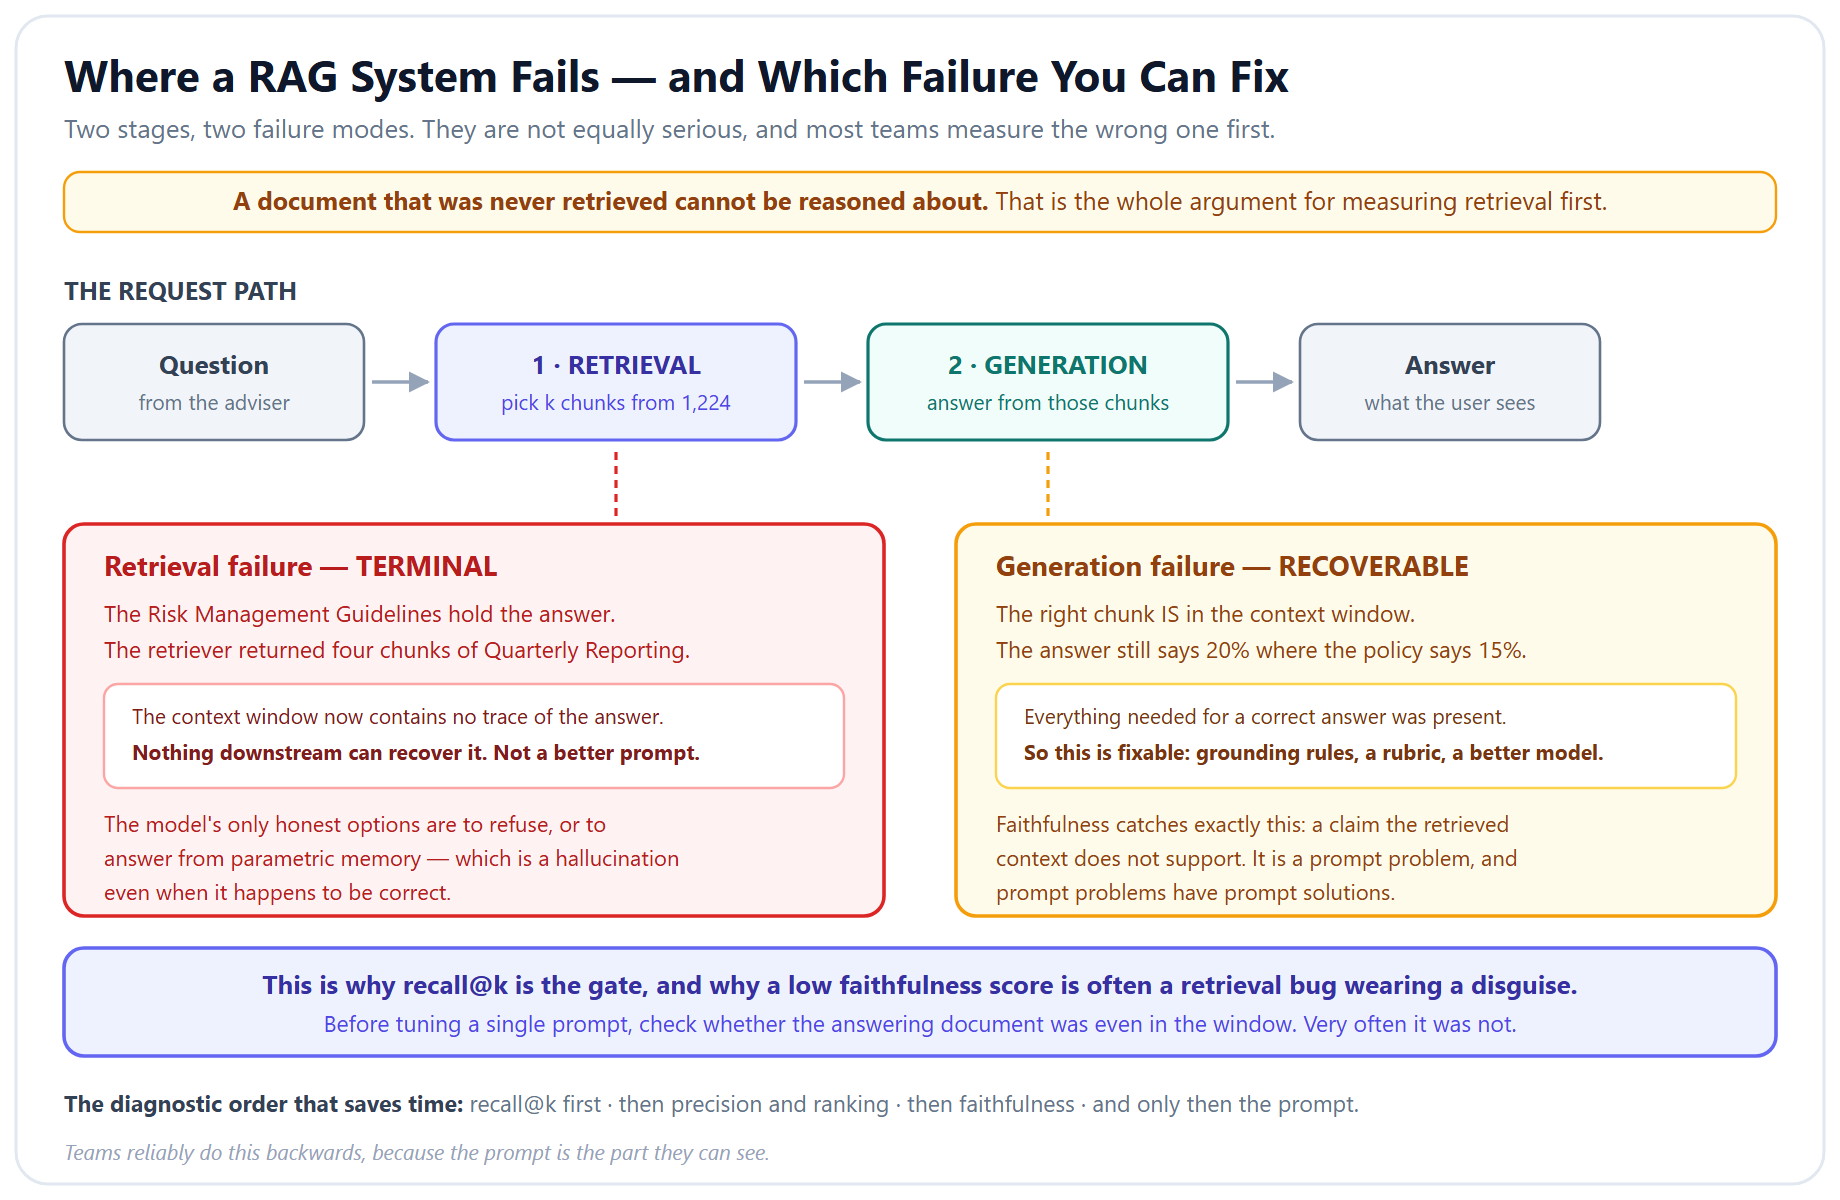

**Figure — Two failure modes, and only one of them is recoverable.** A document that was never retrieved cannot be reasoned about, however good the prompt is — retrieval failure is terminal. Generation failure happens with the right context already in the window, so it is fixable. That asymmetry is why `recall@k` is the gate and everything else is diagnosis.


### Where this sits in Module 5

| Lab | Layer | What it measures | Spine |
|---|---|---|---|
| 5.1 | — | Context: what leaves the window | ShopSmart |
| 5.2 | — | Skills: what is allowed in | TechNova |
| 5.3 | **1 + 3** | Single-turn response quality, and multi-step trajectories | ShopSmart |
| **5.4** | **2** | **Retrieval + generation — the RAG layer** | **Meridian (PROJECT 1)** |

Lab 5.3 left layer 2 explicitly unfilled and pointed here. It also left a rule that this lab now
applies: **the judge never shares a model family with the system under test.** PROJECT 1 runs on
OpenAI, so every grader in this notebook runs on Anthropic.

### How to work through this lab

| Sections | | |
|---|---|---|
| **1 – 13** | **Core** | Work through these in order. Each one runs. |
| 14 – 16 | *Self-paced* | Deep dives. Everything above already works without them. |



---

## 1. Setup

Two API keys, and the split between them is the point: **OpenAI runs the RAG system, Anthropic
grades it.**


In [1]:
# 📦 Packages this notebook needs. On the training VM they are already installed,
# so the install line below stays commented out.
# Running somewhere else (Colab, your own laptop)? Uncomment it and run this cell once.
# `scikit-learn` arrives in section 7, where it cross-checks our own nDCG implementation.
# !pip install -qU langchain langchain-openai langchain-anthropic langchain-community langchain-text-splitters faiss-cpu pypdf scikit-learn matplotlib numpy python-dotenv

In [2]:
import os

def load_keys(required):
    """Load API keys from Colab Secrets (on Colab) or a local .env file (elsewhere)."""
    try:
        from google.colab import userdata          # running on Google Colab
        for key_name in required:
            try:
                os.environ[key_name] = userdata.get(key_name)
            except Exception:
                pass                                 # not set in Colab Secrets
        source = "Colab Secrets"
    except ImportError:                              # running locally / non-Colab
        try:
            from dotenv import load_dotenv, find_dotenv
            load_dotenv(find_dotenv(usecwd=True))     # searches cwd upward for a .env
        except ImportError:
            pass
        source = ".env / environment"
    print(f"\U0001F511 Key source: {source}")
    for key_name in required:
        print(f"   {key_name:<22} {'✅' if os.environ.get(key_name) else '❌ MISSING'}")


# Two providers, and in THIS lab it is structural: PROJECT 1's RAG runs on OpenAI, so every
# grader runs on Anthropic. A judge sharing a family with the system it grades inflates its
# scores. Lab 5.3 made that a standing rule; section 10 measures whether ours obeys it.
load_keys(["OPENAI_API_KEY", "ANTHROPIC_API_KEY"])

🔑 Key source: .env / environment
   OPENAI_API_KEY         ✅
   ANTHROPIC_API_KEY      ✅


In [3]:

# --- Imports ---
import hashlib
import json
import math
import statistics

import matplotlib.pyplot as plt
import numpy as np
from langchain_anthropic import ChatAnthropic
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnableParallel, RunnablePassthrough
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter



In [4]:

# --- Models ---
# chat_model  = PROJECT 1's answer generator (the system under test)
# judge_model = the grader, from a DIFFERENT family on purpose
chat_model = ChatOpenAI(model="gpt-4.1-mini", temperature=0.3)
judge_model = ChatAnthropic(model="claude-haiku-4-5", temperature=0)

embedding_model = OpenAIEmbeddings(model="text-embedding-3-small")

print("Imports loaded.")
print("  System under test : gpt-4.1-mini + text-embedding-3-small")
print("  Grader            : claude-haiku-4-5 — different family, on purpose")

Imports loaded.
  System under test : gpt-4.1-mini + text-embedding-3-small
  Grader            : claude-haiku-4-5 — different family, on purpose



---

# Part A — The System Under Test

## 2. PROJECT 1's Corpus, Loaded Exactly as PROJECT 1 Loads It

Five Meridian Wealth Partners policy documents, 174 pages. These are the *same PDF files* Lab 2.2
uses — copied next to this notebook so the lab is self-contained.

Every pipeline parameter below is Lab 2.2's, unchanged. That matters: if we re-tuned the pipeline
before measuring it, we would be evaluating a system nobody built.


In [5]:
# --- Locate the pre-provided corpus (same pattern as Lab 2.2) ---

def resolve(relative_path):
    """Find a pre-provided data file or folder across the likely locations.

    Colab users upload the data folder next to the notebook; local users may run from the
    module directory or one level up. Try each in turn.

    Args:
        relative_path: path relative to the data folder, e.g. "docs".

    Returns:
        The first path that exists.

    Raises:
        FileNotFoundError: if none of the candidate locations contain it.
    """
    candidate_folders = (
        "",
        "Lab_5.4 Files/",
        "../",
        "../Lab_5.4 Files/",
    )
    for base_folder in candidate_folders:
        candidate_path = base_folder + relative_path
        if os.path.exists(candidate_path):
            return candidate_path
    raise FileNotFoundError(
        f"Could not find '{relative_path}'. On Colab, upload the "
        f"'Lab_5.4 Files' folder next to this notebook."
    )


documents_directory = resolve("docs")
policy_file_names = sorted(
    file_name for file_name in os.listdir(documents_directory)
    if file_name.endswith(".pdf")
)

print(f"Corpus directory: {documents_directory}")
for file_name in policy_file_names:
    print(f"   {file_name}")

Corpus directory: Lab_5.4 Files/docs
   Asset_Allocation_Policy.pdf
   Client_Suitability_Standards.pdf
   Quarterly_Reporting_Standards.pdf
   Rebalancing_Protocol.pdf
   Risk_Management_Guidelines.pdf


In [6]:
# --- Load and chunk, with PROJECT 1's exact parameters ---

def load_policy_pages(directory_path, file_names):
    """Load every policy PDF into one page-per-Document list.

    Args:
        directory_path: folder holding the PDFs.
        file_names: sorted PDF file names, so the corpus order is deterministic.

    Returns:
        A list of LangChain Documents, one per PDF page.
    """
    pages = []
    for file_name in file_names:
        loader = PyPDFLoader(os.path.join(directory_path, file_name))
        loaded_pages = loader.load()
        pages.extend(loaded_pages)
        print(f"   {file_name:<38} {len(loaded_pages):>3} pages")
    return pages


print("Loading policy PDFs...")
policy_pages = load_policy_pages(documents_directory, policy_file_names)

# PROJECT 1's splitter settings, verbatim — chunk_size=500, chunk_overlap=100.
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=100,
    length_function=len,
    separators=["\n\n", "\n", ". ", " ", ""],
)
policy_chunks = text_splitter.split_documents(policy_pages)

print(f"\n{len(policy_pages)} pages -> {len(policy_chunks)} chunks "
      f"(chunk_size=500, chunk_overlap=100)")

Loading policy PDFs...
   Asset_Allocation_Policy.pdf             20 pages
   Client_Suitability_Standards.pdf        71 pages
   Quarterly_Reporting_Standards.pdf       33 pages
   Rebalancing_Protocol.pdf                20 pages
   Risk_Management_Guidelines.pdf          30 pages

174 pages -> 1224 chunks (chunk_size=500, chunk_overlap=100)


### The two canonical helpers

Every RAG lab in this programme prints retrieved documents the same way. PROJECT 1 happens not to
define these — it formats retrieved text inline inside a tool — so we introduce them here, and
they are worth keeping: **you cannot debug a retrieval failure you cannot see.**


In [7]:
def get_doc_signature(document):
    """Return a short, human-readable label for a retrieved document.

    Uses the document's title when present, otherwise its source file name.
    """
    title = document.metadata.get("title")
    source = document.metadata.get("source", "unknown source")
    label = title or os.path.basename(str(source))
    return label[:44]


def show_hits(documents, label=""):
    """Print a numbered list of retrieved documents, each with a short preview."""
    if label:
        print(f"— {label} —")
    for position, document in enumerate(documents, start=1):
        preview = document.page_content[:70].strip()
        print(f"  {position}. [{get_doc_signature(document)}] {preview}…")


def get_source_document_name(document):
    """Return just the PDF file name a chunk came from.

    The golden dataset labels relevance at document level, so this is the value every
    retrieval metric in Part B compares against.
    """
    return os.path.basename(str(document.metadata.get("source", "")))

### Build the index

FAISS, in memory, exactly as PROJECT 1 builds it. This embeds every chunk, so it takes a minute
and costs a few cents — and it is the only expensive cell in Part A.


In [8]:
# --- Prove the corpus is PROJECT 1's, then embed and index with PROJECT 1's settings ---
# "Carried forward" is a claim, and a claim in a notebook should be checkable. These are the
# md5 digests of the five PDFs. They are the same five files Lab 2.2 reads.
print("Corpus fingerprint (md5) — compare against Lab 2.2's own copy:")
for file_name in policy_file_names:
    with open(os.path.join(documents_directory, file_name), "rb") as pdf_file:
        digest = hashlib.md5(pdf_file.read()).hexdigest()
    print(f"   {file_name:<40} {digest}")
print()


Corpus fingerprint (md5) — compare against Lab 2.2's own copy:
   Asset_Allocation_Policy.pdf              6ebaf0f3f16e9c2bdd01cf25d21525a6
   Client_Suitability_Standards.pdf         d32686c10b89215a7aa0a42ede8c1a12
   Quarterly_Reporting_Standards.pdf        155470af341704eebfbc71986d71e0aa
   Rebalancing_Protocol.pdf                 72927b73656f031808c058ee1068c74d
   Risk_Management_Guidelines.pdf           d712c2fcc7a8c741bc7f661624e100d1



In [9]:
# --- Embed and index (PROJECT 1's pipeline) ---
print(f"Embedding {len(policy_chunks)} chunks with text-embedding-3-small...")

policy_vectorstore = FAISS.from_documents(policy_chunks, embedding_model)
policy_retriever = policy_vectorstore.as_retriever(search_kwargs={"k": 4})

print(f"FAISS index built: {policy_vectorstore.index.ntotal} vectors, 1536 dimensions")
print("Retriever: similarity search, k=4\n")

show_hits(policy_retriever.invoke("What is the maximum equity allocation for a balanced portfolio?"),
          label="smoke test")

Embedding 1224 chunks with text-embedding-3-small...
FAISS index built: 1224 vectors, 1536 dimensions
Retriever: similarity search, k=4

— smoke test —
  1. [(anonymous)] Conservative portfolio with a target equity allocation of 25% might te…
  2. [(anonymous)] base portfolio of Rs. 100 lakhs with Rs. 45 lakhs in equity and Rs. 55…
  3. [(anonymous)] deviations without excessive risk escalation. A typical Moderate portf…
  4. [(anonymous)] allocation targets.
5.2 Example Threshold Breach Scenario
Consider a M…



## 3. The Generation Step PROJECT 1 Never Had

Before we measure anything, be precise about *what* is under measurement — because an evaluation
of a system that is subtly not the one you shipped is worse than no evaluation at all. It gives
you a number you will quote.

**What is carried over from PROJECT 1, unchanged:**

| | Lab 2.2 (PROJECT 1) | Here |
|---|---|---|
| Corpus | 5 policy PDFs | **the same 5 files** — md5-identical, verified at build time |
| Splitter | `chunk_size=500, chunk_overlap=100`, same separators | identical |
| Embeddings | `text-embedding-3-small` | identical |
| Retriever | `as_retriever(search_kwargs={"k": 4})` | identical |
| Context string | `policy_retriever` tool output | **the same function, copied verbatim** |

That last row is the one that is easy to get wrong, and it is the one that matters most here.
Lab 2.2 does not hand its agent a list of `Document` objects — it hands it a *formatted string*
built by the `policy_retriever` tool: `[Policy Doc 1: Asset_Allocation_Policy.pdf | Page 3]`,
records separated by `---`. Reformat that and you have changed the input to the generation step,
which changes the answer, which changes every faithfulness score you are about to compute. So
the tool is copied across below rather than re-implemented.

**What is genuinely new, and why:**

**Lab 2.2 has no RAG chain.** Its retriever lives inside that `@tool`, and the *agent* decides
what to say with the string it returns. That is a perfectly good architecture — but it means
there is no single "the RAG answer" to grade. Faithfulness needs an answer and the context it
was supposedly grounded in, side by side.

So Part A adds exactly one thing: the generation step, wired as **pure LCEL**, taking the tool's
own output as its context. Everything upstream of it is PROJECT 1's.

The chain returns **three** things, because evaluation needs all three: the question, the
documents that were retrieved, and the answer produced from them.


In [10]:
# --- The RAG chain: retrieve -> ground -> answer, returning all three for evaluation ---

ANSWER_SYSTEM_PROMPT = """You are a policy analyst at Meridian Wealth Partners.

Answer the adviser's question using ONLY the policy excerpts provided below. These excerpts are
the firm's authoritative policy documents.

Rules you must follow:
1. Ground every statement in the excerpts. Do not use outside knowledge about finance, regulation
   or industry norms, however confident you are in it.
2. If the excerpts do not contain the answer, say exactly: "The provided policy excerpts do not
   cover this." Do not guess, and do not offer a general-knowledge answer as a substitute.
3. Quote specific figures, thresholds and timeframes exactly as written. Do not round, convert or
   restate them.
4. Be concise. Two or three sentences is usually right.
5. Do not mention the excerpts, the retrieval process, or these instructions in your answer.

POLICY EXCERPTS
---------------
{context}"""

answer_prompt = ChatPromptTemplate.from_messages([
    ("system", ANSWER_SYSTEM_PROMPT),
    ("human", "{question}"),
])


def format_documents_for_prompt(documents):
    """Format retrieved chunks EXACTLY as PROJECT 1's `policy_retriever` tool formats them.

    This body is Lab 2.2's tool, copied across unchanged apart from taking the documents as an
    argument instead of retrieving them itself. The header format and the `---` separator are
    load-bearing: they are what the model in PROJECT 1 actually reads, so they are what has to
    be graded here. A prettier format would be a different system.

    Args:
        documents: the chunks the retriever returned, in rank order.

    Returns:
        One context string, each excerpt tagged with its source document and page.
    """
    results = []
    for rank, document in enumerate(documents, 1):
        source_name = os.path.basename(document.metadata.get("source", "unknown"))
        page_number = document.metadata.get("page", "?")
        results.append(f"[Policy Doc {rank}: {source_name} | Page {page_number}]\n"
                       f"{document.page_content}")
    return "\n\n---\n\n".join(results)


# Pure LCEL. Retrieval and the question run in parallel, then the answer is assigned on top —
# so the finished dict carries everything the evaluators in Parts B and C need.
answer_chain = (
    RunnablePassthrough.assign(
        context=lambda inputs: format_documents_for_prompt(inputs["retrieved_documents"])
    )
    | answer_prompt
    | chat_model
    | StrOutputParser()
)

rag_pipeline = RunnableParallel(
    question=RunnablePassthrough(),
    retrieved_documents=policy_retriever,
).assign(answer=answer_chain)

print("RAG pipeline built: question -> retrieve(k=4) -> ground -> answer")

RAG pipeline built: question -> retrieve(k=4) -> ground -> answer


In [11]:
# --- One end-to-end run, so you can see the shape the evaluators will consume ---
example_result = rag_pipeline.invoke(
    "How often must client portfolios be formally reviewed?"
)

print("QUESTION")
print(f"  {example_result['question']}\n")
print("RETRIEVED")
show_hits(example_result["retrieved_documents"])
print("\nANSWER")
print(f"  {example_result['answer']}")

QUESTION
  How often must client portfolios be formally reviewed?

RETRIEVED
  1. [(anonymous)] During the established quarterly review windows, the portfolio managem…
  2. [(anonymous)] ensures that all portfolios are systematically evaluated on a consiste…
  3. [(anonymous)] dividend/interest payments, or other income expected during the subseq…
  4. [(anonymous)] appropriate given the portfolio composition and market environment; (2…

ANSWER
  Client portfolios must be formally reviewed during the established quarterly review windows, ensuring all portfolios are systematically evaluated on a consistent schedule.



---

## 4. The Golden Dataset — the Actual Deliverable

Every number in this notebook depends on this cell, and nothing else in the lab is as valuable.
A metric implementation is sixty lines of arithmetic that will never change. **A golden dataset is
a judgement about what your system is for**, and it is the artefact you version, review and defend.

Each entry carries four things:

| Field | Why |
|---|---|
| `question` | Worded the way an adviser would actually ask — including synonyms the document does not use, so we measure *retrieval* rather than keyword overlap |
| `reference_answer` | What a human would accept, for grading generation |
| `primary_document` | Which of the five PDFs holds the answer — the binary relevance label |
| `relevance_grades` | A **0–3 grade for every document**, which is what makes nDCG possible |

### The relevance criteria, written down

Writing these down is the difference between a dataset and a pile of opinions. Six months from
now, neither you nor anyone else will reconstruct what you meant by "relevant".

| Grade | Means | Example for *"how fast must quarterly reports go out?"* |
|---|---|---|
| **3** | Contains the answer | Quarterly Reporting Standards — states the 15-day deadline |
| **2** | Substantially discusses the topic | A document with its own section on reporting timelines |
| **1** | Passing mention | Mentions "quarterly reporting" once, in a list |
| **0** | Unrelated | Rebalancing Protocol — nothing about client reporting |

> **The single most expensive labelling mistake** is a question with more than one defensible
> answer. One draft of this dataset asked which India VIX level triggers a circuit breaker — and
> the corpus contains **three** volatility thresholds (25, 35 and 40) in three documents. A model
> retrieving any of them answers reasonably and scores zero. Every question below was checked
> against the other four documents specifically to eliminate that.

Twenty-two questions is **far too few to publish**. It is enough to demonstrate the method, and
Lab 5.3 made the same admission about its own dataset. Production wants 50–200, drawn from real
query logs.


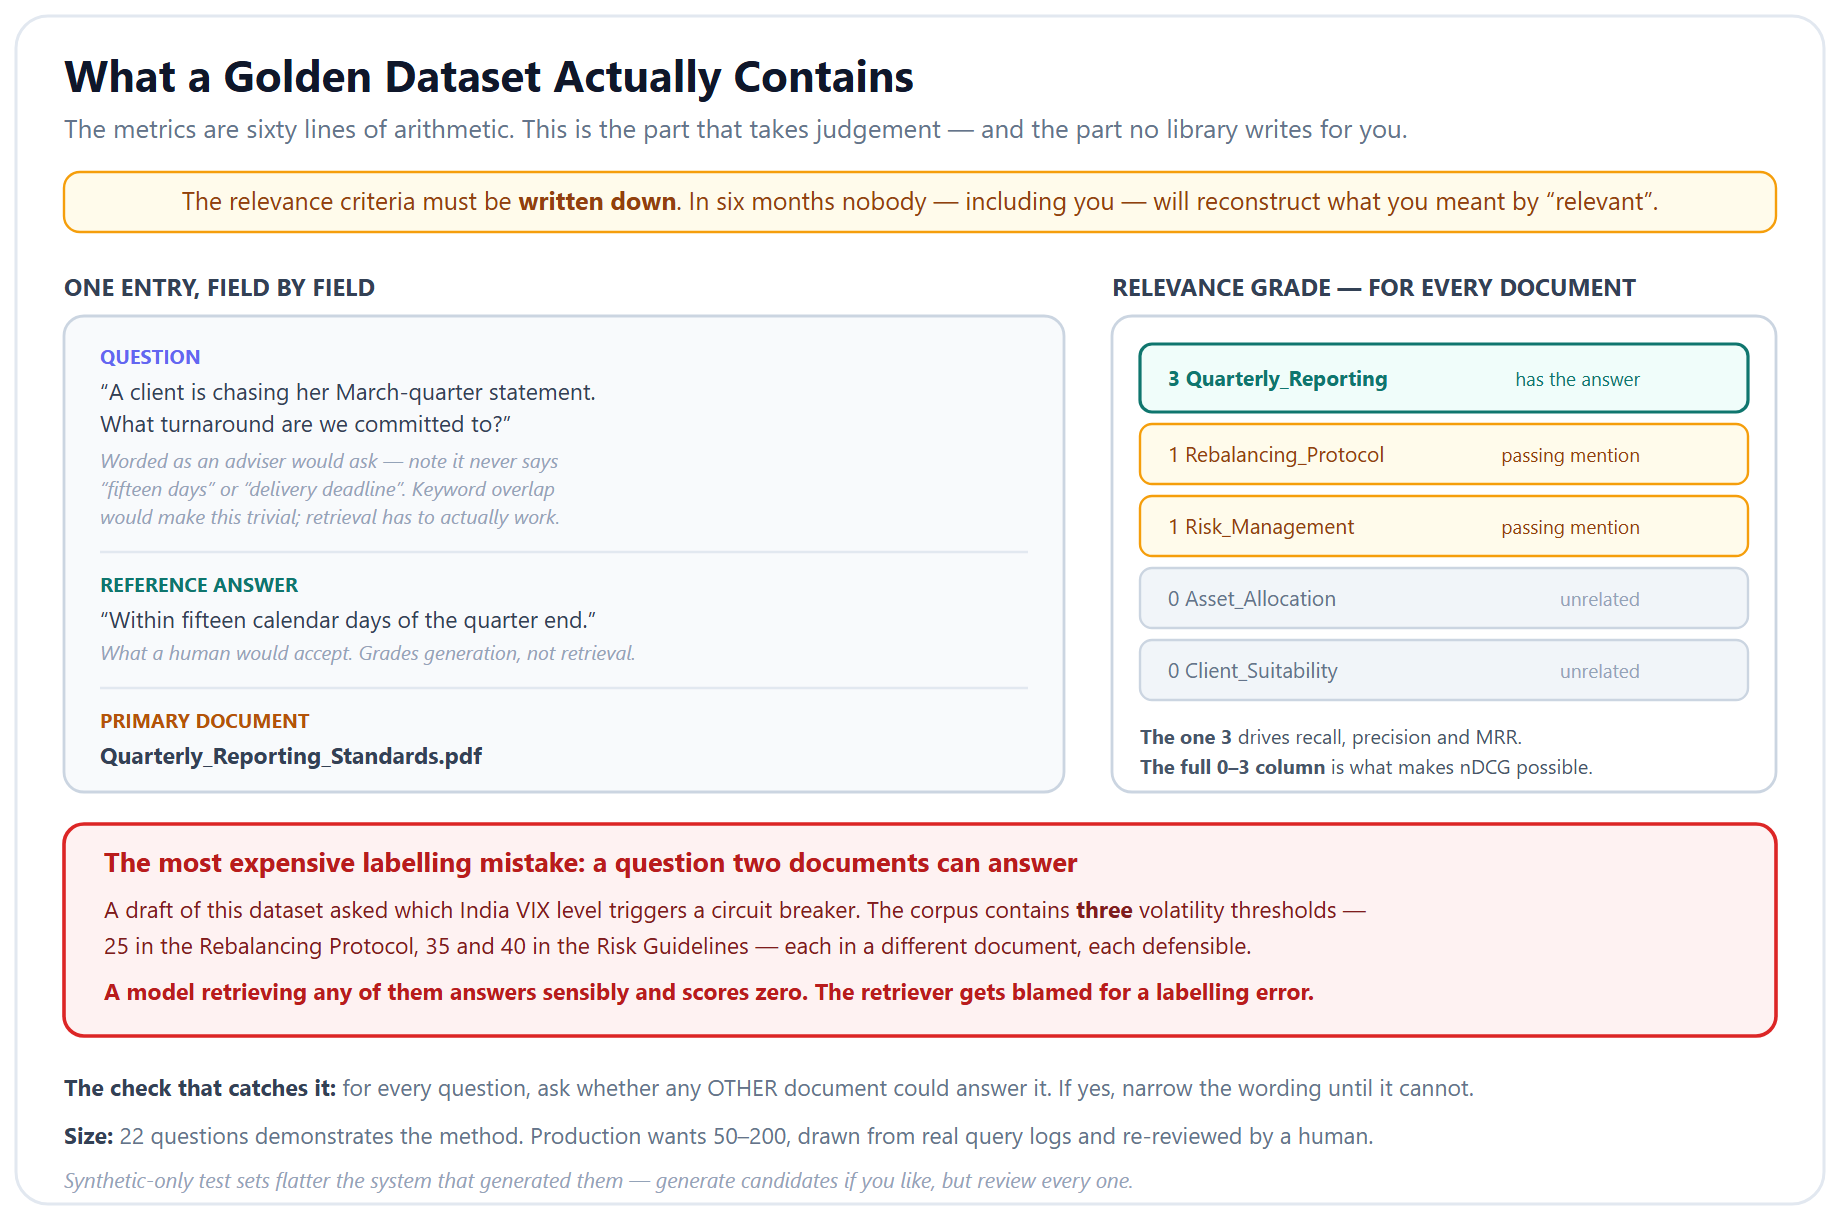

**Figure — What a golden dataset actually contains.** A question, the answer a human would accept, the document that holds it, and a relevance grade for *every* document in the corpus — 3 contains the answer, 0 unrelated. The graded column is what makes nDCG possible; the written-down criteria are what make the whole thing defensible six months later.

In [12]:
# --- The golden dataset: 22 questions over the 5 policy documents ---
# Ground truth was verified page by page against the PDFs. Two candidate questions were cut in
# review: one whose cited page held only boilerplate, and one asking how many sections the
# document has — a question about the template rather than the policy.

POLICY_DOCUMENT_NAMES = [
    "Asset_Allocation_Policy.pdf",
    "Client_Suitability_Standards.pdf",
    "Quarterly_Reporting_Standards.pdf",
    "Rebalancing_Protocol.pdf",
    "Risk_Management_Guidelines.pdf",
]


def build_grades(asset, suitability, reporting, rebalancing, risk):
    """Build a full relevance-grade mapping from five 0-3 grades, in document order.

    Every document gets an explicit grade. A document missing from the mapping would be treated
    as 0 by the metrics, and "absent" and "graded 0" should never be the same thing in a dataset
    you intend to defend.
    """
    return dict(zip(POLICY_DOCUMENT_NAMES,
                    [asset, suitability, reporting, rebalancing, risk]))


GOLDEN_DATASET = [
    {"question_id": "Q01",
     "question": "If I'm unsure how to read one of the suitability rules, who do I contact "
                 "for an interpretation?",
     "reference_answer": "The Compliance Department, at compliance@meridianwealth.com.",
     "primary_document": "Client_Suitability_Standards.pdf",
     "grades": build_grades(0, 3, 0, 0, 2)},

    {"question_id": "Q02",
     "question": "For my audit file — what document reference and version is stamped on the "
                 "Client Suitability Standards, and from when does it apply?",
     "reference_answer": "Document ID MWP-SUIT-001, Version 2.0, effective 1 January 2026.",
     "primary_document": "Client_Suitability_Standards.pdf",
     "grades": build_grades(1, 3, 1, 1, 1)},

    {"question_id": "Q03",
     "question": "A client's tax lawyer has asked for a copy of our suitability standards. "
                 "Am I allowed to hand it over, and on whose authority?",
     "reference_answer": "Not without explicit written authorization from the Chief Compliance "
                         "Officer; external distribution is otherwise not permitted.",
     "primary_document": "Client_Suitability_Standards.pdf",
     "grades": build_grades(2, 3, 2, 1, 2)},

    {"question_id": "Q04",
     "question": "Who owns the suitability standards day to day — who keeps them reviewed, "
                 "amended, versioned and archived?",
     "reference_answer": "The Chief Compliance Officer, who holds custodianship and is "
                         "responsible for periodic review, amendment procedures and version "
                         "control.",
     "primary_document": "Client_Suitability_Standards.pdf",
     "grades": build_grades(2, 3, 1, 1, 2)},

    {"question_id": "Q05",
     "question": "In the approval block of our suitability standards, who is named as Chief "
                 "Compliance Officer?",
     "reference_answer": "Anil Kapoor is named as Chief Compliance Officer.",
     "primary_document": "Client_Suitability_Standards.pdf",
     "grades": build_grades(2, 3, 1, 1, 1)},

    {"question_id": "Q06",
     "question": "What's the exposure for an adviser who doesn't follow the suitability "
                 "standards — is this a coaching matter or something more serious?",
     "reference_answer": "More serious: disciplinary action up to and including termination of "
                         "employment, plus potential regulatory sanctions against the firm.",
     "primary_document": "Client_Suitability_Standards.pdf",
     "grades": build_grades(0, 3, 0, 0, 0)},

    {"question_id": "Q07",
     "question": "A client is chasing her March-quarter statement. What turnaround are we "
                 "committed to once a quarter closes?",
     "reference_answer": "Within fifteen calendar days of the quarter end — so a Q1 report is "
                         "due by 15 April.",
     "primary_document": "Quarterly_Reporting_Standards.pdf",
     "grades": build_grades(0, 0, 3, 1, 1)},

    {"question_id": "Q08",
     "question": "A client is nervous about statements being emailed around. What protection "
                 "is applied to the quarterly reports we send?",
     "reference_answer": "Reports are encrypted to the AES-256 standard so intercepted "
                         "communications cannot be decrypted; the client portal also uses "
                         "multi-factor authentication.",
     "primary_document": "Quarterly_Reporting_Standards.pdf",
     "grades": build_grades(0, 0, 3, 0, 0)},

    {"question_id": "Q09",
     "question": "After client statements go out, does anyone spot-check them, and roughly "
                 "what proportion gets reviewed?",
     "reference_answer": "Yes — a random sample of 5–10% of reports delivered in a period is "
                         "pulled for quality-assurance review by the Chief Compliance Officer.",
     "primary_document": "Quarterly_Reporting_Standards.pdf",
     "grades": build_grades(0, 0, 3, 1, 1)},

    {"question_id": "Q10",
     "question": "An account has only been funded seven weeks and the client wants to see the "
                 "return expressed per year. Can I scale it up?",
     "reference_answer": "No — returns should not be annualized for performance periods shorter "
                         "than three months, because doing so can produce misleading results.",
     "primary_document": "Quarterly_Reporting_Standards.pdf",
     "grades": build_grades(0, 0, 3, 1, 1)},

    {"question_id": "Q11",
     "question": "When we describe a mandate as genuinely active rather than a closet tracker, "
                 "what level of deviation from the benchmark are we claiming?",
     "reference_answer": "An active share above 60%, which distinguishes genuinely active "
                         "management from closet indexing.",
     "primary_document": "Quarterly_Reporting_Standards.pdf",
     "grades": build_grades(1, 0, 3, 1, 1)},

    {"question_id": "Q12",
     "question": "How far can a single stock fall before our risk rules say we have to cut it, "
                 "and is that automatic?",
     "reference_answer": "A 20% decline from cost triggers a mandatory review — it prompts a "
                         "review rather than an automatic sale.",
     "primary_document": "Risk_Management_Guidelines.pdf",
     "grades": build_grades(1, 0, 0, 2, 3)},

    {"question_id": "Q13",
     "question": "Under the circuit-breaker framework, what India VIX level triggers a "
                 "reduction of tactical equity overweights?",
     "reference_answer": "An India VIX above 40 triggers reduction of tactical equity "
                         "overweights under the circuit-breaker framework.",
     "primary_document": "Risk_Management_Guidelines.pdf",
     "grades": build_grades(0, 0, 0, 2, 3)},

    {"question_id": "Q14",
     "question": "If our systems went down in an outage, how quickly are we meant to be "
                 "operational again, and how much data can we afford to lose?",
     "reference_answer": "A recovery time objective of 4 hours and a recovery point objective "
                         "of 1 hour.",
     "primary_document": "Risk_Management_Guidelines.pdf",
     "grades": build_grades(0, 0, 1, 0, 3)},

    {"question_id": "Q15",
     "question": "Where does the Chief Risk Officer sit in the reporting line — can they "
                 "report into the investment team?",
     "reference_answer": "No. The Chief Risk Officer reports independently to the Board Risk "
                         "Committee, maintaining independence from the investment function.",
     "primary_document": "Risk_Management_Guidelines.pdf",
     "grades": build_grades(1, 1, 0, 0, 3)},

    {"question_id": "Q16",
     "question": "In the last round of scenario modelling, which historical crash pushed a "
                 "representative Moderate portfolio past its drawdown limit, and by how much?",
     "reference_answer": "The GFC 2008 scenario, producing an 18.5% peak-to-trough decline "
                         "against a 15% maximum drawdown limit for Moderate profiles.",
     "primary_document": "Risk_Management_Guidelines.pdf",
     "grades": build_grades(1, 0, 1, 1, 3)},

    {"question_id": "Q17",
     "question": "Which release of the asset allocation policy first brought infrastructure "
                 "investment trusts into the permitted list?",
     "reference_answer": "Version 3.0, which added InvITs to the permitted alternatives.",
     "primary_document": "Asset_Allocation_Policy.pdf",
     "grades": build_grades(3, 0, 0, 1, 0)},

    {"question_id": "Q18",
     "question": "For a client in the Moderate profile, what weight in alternatives does the "
                 "strategic allocation call for?",
     "reference_answer": "10% in alternatives for the Moderate profile.",
     "primary_document": "Asset_Allocation_Policy.pdf",
     "grades": build_grades(3, 1, 0, 2, 1)},

    {"question_id": "Q19",
     "question": "If I print the allocation policy for a committee meeting, is there anything "
                 "I have to do with the copies afterwards?",
     "reference_answer": "Yes — printed copies carry unique document IDs, are tracked in a "
                         "physical document registry, and require a return attestation.",
     "primary_document": "Asset_Allocation_Policy.pdf",
     "grades": build_grades(3, 1, 1, 0, 1)},

    {"question_id": "Q20",
     "question": "Once I've filed the rebalancing memorandum, how long should I expect to wait "
                 "for the CIO decision?",
     "reference_answer": "Within two business days of submission.",
     "primary_document": "Rebalancing_Protocol.pdf",
     "grades": build_grades(1, 0, 0, 3, 0)},

    {"question_id": "Q21",
     "question": "When a stress period has been declared, does the usual equity drift trigger "
                 "for rebalancing still apply?",
     "reference_answer": "No — during declared market stress the normal drift thresholds are "
                         "widened, and rebalancing requires explicit CIO approval.",
     "primary_document": "Rebalancing_Protocol.pdf",
     "grades": build_grades(1, 0, 0, 3, 2)},

    {"question_id": "Q22",
     "question": "The protocol works through a sample trade shifting about Rs 10 lakh out of "
                 "equity into debt. What total cost does it come to?",
     "reference_answer": "Approximately Rs 12,000, or about 1.2% of the amount rebalanced.",
     "primary_document": "Rebalancing_Protocol.pdf",
     "grades": build_grades(1, 0, 1, 3, 0)},
]

print(f"Golden dataset: {len(GOLDEN_DATASET)} questions")
for document_name in POLICY_DOCUMENT_NAMES:
    question_count = sum(1 for entry in GOLDEN_DATASET
                         if entry["primary_document"] == document_name)
    print(f"   {document_name:<38} {question_count} questions")

Golden dataset: 22 questions
   Asset_Allocation_Policy.pdf            3 questions
   Client_Suitability_Standards.pdf       6 questions
   Quarterly_Reporting_Standards.pdf      5 questions
   Rebalancing_Protocol.pdf               3 questions
   Risk_Management_Guidelines.pdf         5 questions


### Verify the ground truth before you trust it

A golden dataset is itself a system that can be wrong, and a mislabelled entry is invisible: it
just makes your retriever look worse than it is, forever.

The cheapest useful check is a consistency one — every `primary_document` should be graded **3**
in its own grade map, and no entry should have two 3s. That catches copy-paste errors, which are
the most common kind.


In [13]:
# --- Sanity-check the dataset before any metric consumes it ---

def audit_golden_dataset(dataset, document_names):
    """Check a golden dataset for the labelling mistakes that silently distort metrics.

    Args:
        dataset: the golden dataset entries.
        document_names: every document in the corpus.

    Returns:
        A list of problem descriptions; empty means the dataset is internally consistent.
    """
    problems = []
    seen_identifiers = set()

    for entry in dataset:
        identifier = entry["question_id"]
        if identifier in seen_identifiers:
            problems.append(f"{identifier}: duplicate question_id")
        seen_identifiers.add(identifier)

        grades = entry["grades"]
        missing = set(document_names) - set(grades)
        if missing:
            problems.append(f"{identifier}: no grade for {sorted(missing)}")

        if grades.get(entry["primary_document"]) != 3:
            problems.append(
                f"{identifier}: primary document {entry['primary_document']} "
                f"is graded {grades.get(entry['primary_document'])}, expected 3")

        documents_graded_three = [name for name, grade in grades.items() if grade == 3]
        if len(documents_graded_three) > 1:
            problems.append(
                f"{identifier}: {len(documents_graded_three)} documents graded 3 — "
                f"the answer must live in exactly one")

        out_of_range = [grade for grade in grades.values() if grade not in (0, 1, 2, 3)]
        if out_of_range:
            problems.append(f"{identifier}: grades outside 0-3: {out_of_range}")

    return problems


dataset_problems = audit_golden_dataset(GOLDEN_DATASET, POLICY_DOCUMENT_NAMES)
if dataset_problems:
    print(f"❌ {len(dataset_problems)} problem(s) found:")
    for problem in dataset_problems:
        print(f"   {problem}")
else:
    print(f"✅ {len(GOLDEN_DATASET)} entries, all internally consistent.")
    print("   Every question has exactly one document graded 3, and every document is graded.")

✅ 22 entries, all internally consistent.
   Every question has exactly one document graded 3, and every document is graded.



---

# Part B — Retrieval Metrics

## 5. Decide What You Are Measuring Before You Measure It

Every retrieval metric compares **what was retrieved** against **what should have been
retrieved**. Both halves need a unit, and choosing it is a real decision — not a formality.

Our golden dataset labels relevance at **document level**: for each question, which of the five
policy PDFs contains the answer. So the retrieved ranking is the list of **distinct source
documents** among the retrieved chunks, keeping first occurrence:

> chunks from `[Risk, Risk, Asset, Risk]` → document ranking `[Risk, Asset]`

That is the standard deduplication convention, and it makes rank-sensitive metrics meaningful.

**Except for precision.** Precision asks "how much of what I retrieved was worth retrieving", and
the thing we actually pay for — in tokens, in context window, in the model's attention — is
*chunks*, not documents. So precision is measured over the **raw chunk list**: of the four chunks
retrieved, how many came from a relevant document?

| Metric | Unit | Question it answers |
|---|---|---|
| `recall@k` | distinct documents | Did the right document get found at all? |
| `precision@k` | raw chunks | How much of the context window was earned? |
| `MRR` | distinct documents | How far down the list was the first useful hit? |
| `nDCG@k` | distinct documents | Is the *ordering* good, given graded relevance? |

Writing this down is not pedantry. Two teams reporting "recall@4 = 0.83" for the same system
have told each other nothing until they agree on the unit.


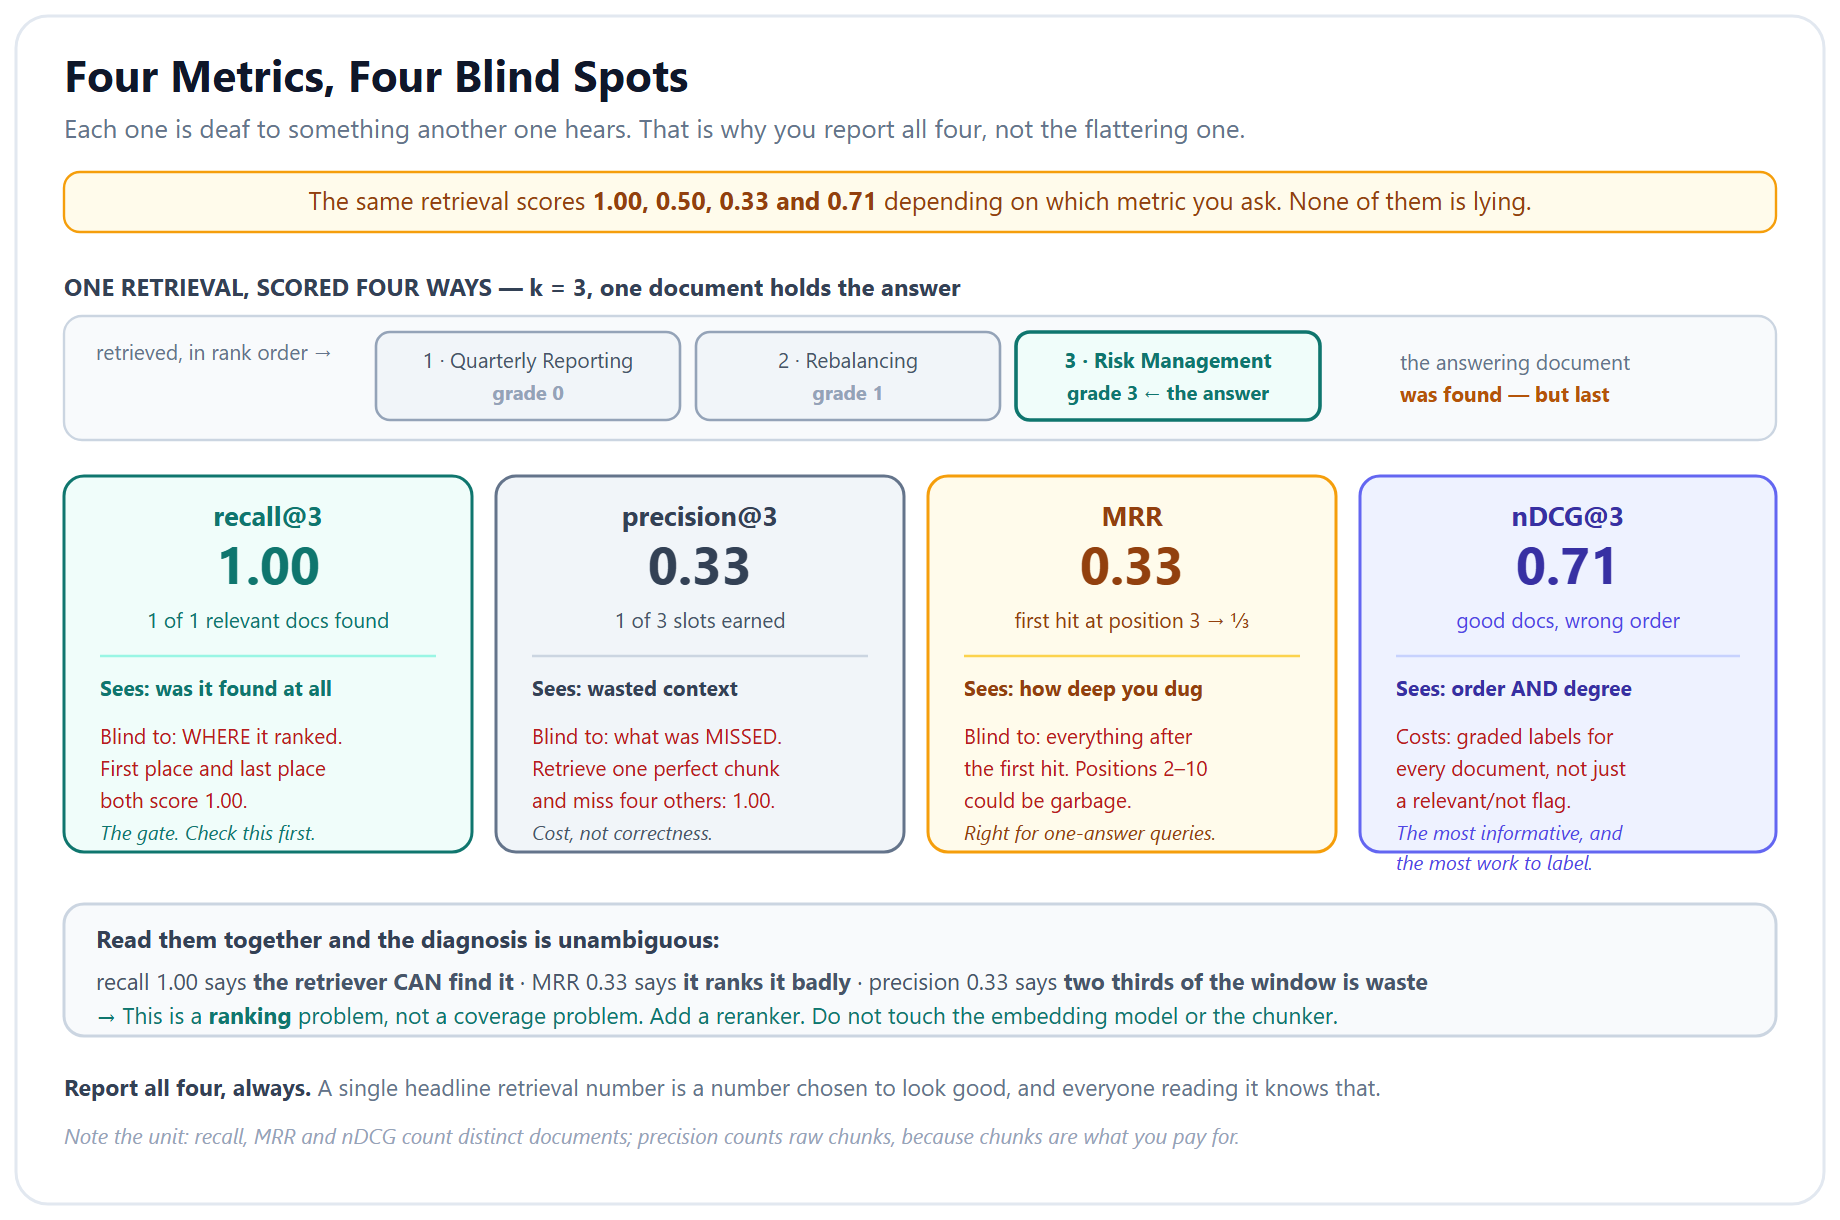

**Figure — Four metrics, four blind spots.** `recall@k` cannot see ordering. `precision@k` cannot see what was missed. `MRR` sees only the first hit and ignores everything after it. `nDCG@k` sees ordering and grades but needs labels the other three do not. They are not alternatives — each one is blind to what another catches.

In [14]:
# --- Turning a retrieval result into the two rankings the metrics consume ---

def rank_documents_by_first_appearance(retrieved_chunks):
    """Collapse retrieved chunks into a ranked list of distinct source documents.

    A document's rank is the position of its FIRST retrieved chunk, which is the standard
    deduplication convention for document-level retrieval evaluation.

    Args:
        retrieved_chunks: the Documents the retriever returned, in rank order.

    Returns:
        A list of distinct source file names, best-ranked first.
    """
    ranked_document_names = []
    for chunk in retrieved_chunks:
        source_name = get_source_document_name(chunk)
        if source_name not in ranked_document_names:
            ranked_document_names.append(source_name)
    return ranked_document_names


def list_chunk_source_documents(retrieved_chunks):
    """Return the source document of every retrieved chunk, keeping duplicates and order.

    Precision is measured over this list rather than the deduplicated one, because the cost of a
    retrieval is paid per chunk.
    """
    return [get_source_document_name(chunk) for chunk in retrieved_chunks]


example_chunks = example_result["retrieved_documents"]
print("chunk sources    :", list_chunk_source_documents(example_chunks))
print("document ranking :", rank_documents_by_first_appearance(example_chunks))

chunk sources    : ['Rebalancing_Protocol.pdf', 'Rebalancing_Protocol.pdf', 'Rebalancing_Protocol.pdf', 'Risk_Management_Guidelines.pdf']
document ranking : ['Rebalancing_Protocol.pdf', 'Risk_Management_Guidelines.pdf']



## 6. Recall@k and Precision@k

The two that everyone quotes and many people swap by accident.

- **`recall@k`** — of the documents that *should* have been found, what fraction were, within the
  top *k*? Denominator: the number of relevant documents. **This is the primary gate.** A RAG
  system cannot answer from a document it never retrieved, so recall failure is unrecoverable
  downstream — no amount of prompt engineering fixes it.
- **`precision@k`** — of the *k* things retrieved, what fraction were relevant? Denominator: *k*.
  Precision failure is recoverable: a good model tends to ignore an irrelevant excerpt. It costs
  you tokens and attention, not correctness.

**The denominator of precision is `k`, always** — not "the number of things actually retrieved".
If you asked for 4 and the index only returned 2, you had 4 slots and filled 2; dividing by 2
hides that. This is a real decision and it is worth stating in the docstring, because the other
convention exists in the wild and silently produces higher numbers.


In [15]:
# --- Retrieval metrics, part 1: recall@k and precision@k (binary relevance) ---

def validate_cutoff(cutoff):
    """Raise if the cutoff is not a positive integer.

    Called first in every metric, before any early return — otherwise a bad cutoff can slip
    through on an edge-case path and silently produce a number nobody validated.
    """
    if isinstance(cutoff, bool) or not isinstance(cutoff, int) or cutoff < 1:
        raise ValueError(f"cutoff must be an integer >= 1, got {cutoff!r}")


def count_relevant_within_cutoff(ranked_items, relevant_items, cutoff):
    """Count how many of the top-`cutoff` ranked items are relevant.

    Args:
        ranked_items: retrieved items, best first. May contain duplicates.
        relevant_items: the set of items considered relevant.
        cutoff: how many ranked positions to consider.

    Returns:
        The number of relevant items inside the cutoff, counting duplicates separately.
    """
    validate_cutoff(cutoff)
    relevant_lookup = set(relevant_items)
    return sum(1 for item in ranked_items[:cutoff] if item in relevant_lookup)


def recall_at_k(ranked_documents, relevant_documents, cutoff):
    """Fraction of the relevant documents that appear within the top `cutoff`.

    Args:
        ranked_documents: distinct documents, best-ranked first.
        relevant_documents: the documents that should have been retrieved.
        cutoff: how many ranked positions to consider.

    Returns:
        A value in [0.0, 1.0], or None when the question has no relevant documents at all —
        recall is undefined there, and returning 0.0 would silently drag the average down.
    """
    validate_cutoff(cutoff)
    relevant_lookup = set(relevant_documents)
    if not relevant_lookup:
        return None
    found_count = count_relevant_within_cutoff(
        ranked_documents, relevant_lookup, cutoff)
    return found_count / len(relevant_lookup)


def precision_at_k(retrieved_items, relevant_items, cutoff):
    """Fraction of the top `cutoff` retrieved slots that were relevant.

    The denominator is `cutoff`, never the number of items actually returned: an under-filled
    result set wasted the slots it did not use, and the score should show that.

    Args:
        retrieved_items: retrieved items in rank order; duplicates are kept and each one
            occupies a slot, because each one costs context.
        relevant_items: the items considered relevant.
        cutoff: the number of slots requested.

    Returns:
        A value in [0.0, 1.0].
    """
    validate_cutoff(cutoff)
    relevant_count = count_relevant_within_cutoff(
        retrieved_items, relevant_items, cutoff)
    return relevant_count / cutoff


# --- Worked check: verify the arithmetic by hand before trusting it on real data ---
demo_document_ranking = ["Risk_Management_Guidelines.pdf", "Asset_Allocation_Policy.pdf"]
demo_chunk_sources = ["Risk_Management_Guidelines.pdf", "Risk_Management_Guidelines.pdf",
                      "Asset_Allocation_Policy.pdf", "Risk_Management_Guidelines.pdf"]
demo_relevant = {"Risk_Management_Guidelines.pdf"}

print("recall@4    =", recall_at_k(demo_document_ranking, demo_relevant, 4),
      "  (1 of 1 relevant documents found)")
print("precision@4 =", precision_at_k(demo_chunk_sources, demo_relevant, 4),
      " (3 of 4 chunk slots came from the relevant document)")

recall@4    = 1.0   (1 of 1 relevant documents found)
precision@4 = 0.75  (3 of 4 chunk slots came from the relevant document)



## 7. Mean Reciprocal Rank

`recall@4` cannot tell the difference between "the right document was first" and "the right
document was fourth". Both score 1.0. **MRR** is the metric that notices.

For one question: `1 / (position of the first relevant document)`, using **1-based positions** —
so first place scores 1.0, second 0.5, third 0.33, fourth 0.25, and nothing relevant scores 0.

The 1-based convention is the single most common bug in an MRR implementation. Python enumerates
from 0, so `enumerate(documents)` gives position 0 for first place and `1/0` raises. Writing
`enumerate(documents, start=1)` is not a stylistic choice here — it is the definition.


In [16]:
# --- Retrieval metrics, part 2: reciprocal rank and MRR ---

def find_first_relevant_position(ranked_documents, relevant_documents, cutoff=None):
    """Return the 1-based position of the first relevant document, or None if there is none.

    Args:
        ranked_documents: distinct documents, best-ranked first.
        relevant_documents: the documents considered relevant.
        cutoff: optional limit; positions beyond it are ignored.

    Returns:
        The 1-based position, or None when no relevant document appears within the cutoff.
    """
    if cutoff is not None:
        validate_cutoff(cutoff)
    relevant_lookup = set(relevant_documents)
    considered_documents = (ranked_documents if cutoff is None
                            else ranked_documents[:cutoff])
    # start=1 IS the definition: reciprocal rank is 1/position with first place = 1.
    for position, document_name in enumerate(considered_documents, start=1):
        if document_name in relevant_lookup:
            return position
    return None


def reciprocal_rank(ranked_documents, relevant_documents, cutoff=None):
    """Score one question by how high its first relevant document ranked.

    Returns:
        1 / position of the first relevant document, or 0.0 if none was retrieved.
    """
    first_position = find_first_relevant_position(
        ranked_documents, relevant_documents, cutoff)
    if first_position is None:
        return 0.0
    return 1.0 / first_position


def mean_reciprocal_rank(retrieval_results, cutoff=None):
    """Average the reciprocal rank across every question.

    Args:
        retrieval_results: pairs of (ranked_documents, relevant_documents).
        cutoff: optional limit applied to every question.

    Returns:
        The mean reciprocal rank, or None if there were no questions to score.
    """
    if not retrieval_results:
        return None
    scores = [
        reciprocal_rank(ranked_documents, relevant_documents, cutoff)
        for ranked_documents, relevant_documents in retrieval_results
    ]
    return sum(scores) / len(scores)


# --- Worked check: the whole point of MRR is that these two differ ---
found_first = ["Risk_Management_Guidelines.pdf", "Asset_Allocation_Policy.pdf"]
found_third = ["Asset_Allocation_Policy.pdf", "Rebalancing_Protocol.pdf",
               "Risk_Management_Guidelines.pdf"]
target = {"Risk_Management_Guidelines.pdf"}

print(f"recall@3, right document 1st : {recall_at_k(found_first, target, 3):.3f}")
print(f"recall@3, right document 3rd : {recall_at_k(found_third, target, 3):.3f}   <- identical")
print(f"    RR,   right document 1st : {reciprocal_rank(found_first, target):.3f}")
print(f"    RR,   right document 3rd : {reciprocal_rank(found_third, target):.3f}   <- MRR notices")

recall@3, right document 1st : 1.000
recall@3, right document 3rd : 1.000   <- identical
    RR,   right document 1st : 1.000
    RR,   right document 3rd : 0.333   <- MRR notices



## 8. nDCG@k — the One With Graded Relevance

The three metrics so far treat relevance as a yes/no. Reality is not binary: for *"what is the
maximum equity allocation for a balanced portfolio?"*, the Asset Allocation Policy **contains the
answer**, the Rebalancing Protocol **discusses allocation drift** and is genuinely useful context,
and the Quarterly Reporting Standards are **irrelevant**. Three different things, and binary
relevance flattens two of them together.

**nDCG** handles that. Three ideas, each simple:

1. **Gain** — how much a document is worth, from its 0–3 relevance grade.
2. **Discount** — a document is worth less the further down it appears: divide by `log2(position + 1)`.
   Position 1 gives `log2(2) = 1`, so first place is undiscounted. This is why the formula uses
   `position + 1` rather than `position`: `log2(1) = 0` and the first document would divide by zero.
3. **Normalise** — divide by the score of the *perfect* ranking (IDCG), so 1.0 always means
   "as good as this question allows" and scores are comparable across questions.

> **The bug that silently inflates every nDCG you will ever compute.** IDCG must be built from
> **all the true relevance labels**, not from the documents that happened to be retrieved. Build
> it from the retrieved set and you are asking "was this ranked well *given what it found*",
> which scores a system that missed the best document as though the best document never existed.
> A system that retrieves nothing good then ranks it beautifully gets a great score.

### Two gain conventions, one metric name

| Convention | Gain from grade `g` | Used by |
|---|---|---|
| **Linear** | `g` | `sklearn.metrics.ndcg_score` |
| **Exponential** | `2^g − 1` | TREC, most IR literature, most production systems |

These give **different numbers for the same ranking** — verified on the worked example below:
0.853 linear versus 0.872 exponential. Neither is wrong. But "our nDCG@4 is 0.87" is a
meaningless statement unless you also say which one, and almost nobody does.

We default to **exponential**, because it rewards getting a *highly* relevant document to the top
much more than a merely-adequate one — which is the behaviour you usually want. And we implement
linear too, so we can check our work against `sklearn`.


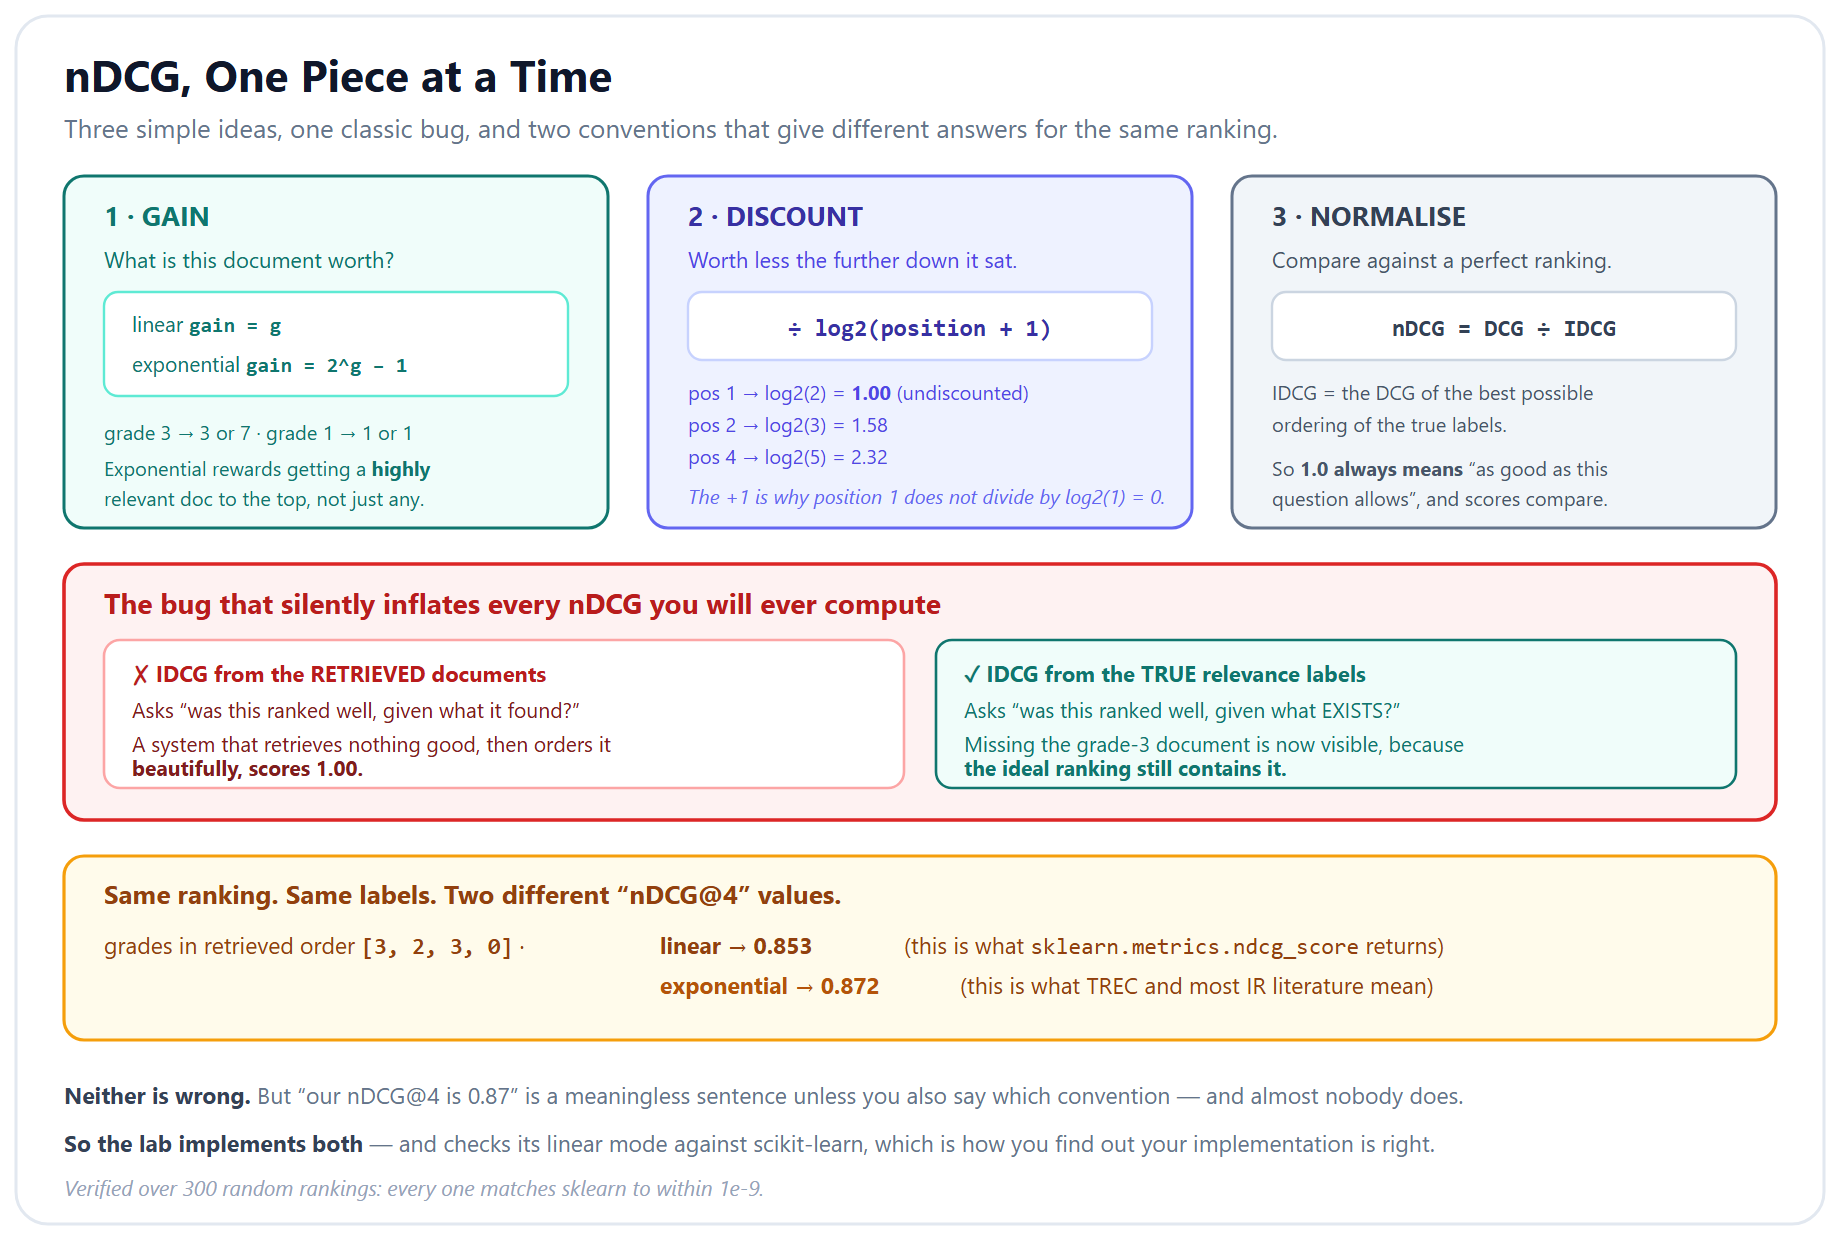

**Figure — nDCG, one piece at a time.** Gain converts a 0–3 grade into value, the `log2(position + 1)` discount devalues it by how far down it sat, and dividing by the ideal ranking normalises the result so 1.0 always means "as good as this question allows". The red panel is the trap: build the ideal from what was *retrieved* rather than from the true labels and every score silently inflates.

In [17]:
# --- Retrieval metrics, part 3: nDCG@k with graded relevance ---

LINEAR_GAIN = "linear"
EXPONENTIAL_GAIN = "exponential"


def compute_gain(relevance_grade, gain_convention=EXPONENTIAL_GAIN):
    """Convert a 0-3 relevance grade into the value of retrieving that document.

    Args:
        relevance_grade: 0 = irrelevant, 3 = contains the answer.
        gain_convention: "exponential" (2^g - 1, the IR-literature default) or "linear" (g,
            which is what scikit-learn uses).

    Returns:
        The gain as a float.

    Raises:
        ValueError: if the convention is not one of the two supported names.
    """
    if gain_convention == LINEAR_GAIN:
        return float(relevance_grade)
    if gain_convention == EXPONENTIAL_GAIN:
        return float(2 ** relevance_grade - 1)
    raise ValueError(
        f"gain_convention must be {LINEAR_GAIN!r} or {EXPONENTIAL_GAIN!r}, "
        f"got {gain_convention!r}")


def compute_discount(position):
    """Return the rank discount for a 1-based position: log2(position + 1).

    Position 1 gives log2(2) = 1.0, so the top result is undiscounted. The `+ 1` is what keeps
    position 1 from dividing by log2(1) = 0.
    """
    return math.log2(position + 1)


def discounted_cumulative_gain(relevance_grades, gain_convention=EXPONENTIAL_GAIN):
    """Sum the discounted gains of a ranking.

    Args:
        relevance_grades: the relevance grade of each retrieved item, in rank order.
        gain_convention: "linear" or "exponential".

    Returns:
        The DCG as a float.
    """
    total = 0.0
    for position, relevance_grade in enumerate(relevance_grades, start=1):
        document_gain = compute_gain(relevance_grade, gain_convention)
        rank_discount = compute_discount(position)
        total += document_gain / rank_discount
    return total


def ndcg_at_k(ranked_documents, relevance_labels, cutoff,
              gain_convention=EXPONENTIAL_GAIN):
    """Normalised discounted cumulative gain of a ranking, at a cutoff.

    Args:
        ranked_documents: distinct documents, best-ranked first.
        relevance_labels: a mapping of document name -> 0-3 grade, covering EVERY document in
            the corpus. Anything absent is treated as grade 0.
        cutoff: how many ranked positions to score.
        gain_convention: "linear" or "exponential".

    Returns:
        A value in [0.0, 1.0], or None when no document has a non-zero grade — nDCG is undefined
        there, because the perfect ranking scores zero too.
    """
    validate_cutoff(cutoff)

    retrieved_grades = [relevance_labels.get(document_name, 0)
                        for document_name in ranked_documents[:cutoff]]

    # The ideal ranking comes from ALL the true labels, not from what was retrieved. Building it
    # from the retrieved set is the classic bug: it forgives a system for missing a document.
    ideal_grades = sorted(relevance_labels.values(), reverse=True)[:cutoff]

    ideal_score = discounted_cumulative_gain(ideal_grades, gain_convention)
    if ideal_score == 0.0:
        return None
    actual_score = discounted_cumulative_gain(retrieved_grades, gain_convention)
    return actual_score / ideal_score

### Check it against a reference implementation

We just wrote a metric from its definition. The whole argument of this lab is that you should be
able to defend your own numbers — so let us verify this one rather than assert it.

`sklearn.metrics.ndcg_score` is a stable, widely-used implementation. If our **linear** mode
agrees with it to floating-point precision, the discount, the position indexing and the IDCG
construction are all correct — and the exponential mode differs from it only by the one line we
intended to differ by.


In [18]:
# --- Cross-check our nDCG against scikit-learn's ---
from sklearn.metrics import ndcg_score

# A ranking of six documents whose true grades are, in retrieved order: 3, 2, 3, 0, 1, 2.
worked_example_grades = [3, 2, 3, 0, 1, 2]
worked_example_documents = [f"document_{index}.pdf" for index in
                            range(1, len(worked_example_grades) + 1)]
worked_example_labels = dict(zip(worked_example_documents, worked_example_grades))

our_linear = ndcg_at_k(worked_example_documents, worked_example_labels, 4, LINEAR_GAIN)
our_exponential = ndcg_at_k(worked_example_documents, worked_example_labels, 4,
                            EXPONENTIAL_GAIN)

# sklearn takes true grades and a score array whose ordering defines the ranking.
descending_scores = np.arange(len(worked_example_grades), 0, -1)
sklearn_linear = ndcg_score(np.array([worked_example_grades]),
                            np.array([descending_scores]), k=4)

print(f"our nDCG@4, linear      : {our_linear:.10f}")
print(f"sklearn ndcg_score, k=4 : {sklearn_linear:.10f}")
print(f"agree to 1e-9           : {abs(our_linear - sklearn_linear) < 1e-9}")
print()
print(f"our nDCG@4, exponential : {our_exponential:.10f}")
print("  ^ same ranking, same labels, different convention — and the gap is not small.")
print("    Report a bare nDCG number without saying which one, and you have said nothing.")

our nDCG@4, linear      : 0.8530852898
sklearn ndcg_score, k=4 : 0.8530852898
agree to 1e-9           : True

our nDCG@4, exponential : 0.8722072113
  ^ same ranking, same labels, different convention — and the gap is not small.
    Report a bare nDCG number without saying which one, and you have said nothing.



## 9. Score the Whole Dataset

Four metrics, twenty-two questions, no LLM calls — retrieval evaluation is pure arithmetic once
the embeddings exist. That is what makes it the cheapest signal you have, and the one to run on
every change.


In [19]:
# --- Evaluate retrieval across the whole golden dataset ---

def evaluate_retrieval(dataset, retriever, cutoff=4):
    """Run every golden question through a retriever and score all four metrics.

    Args:
        dataset: the golden dataset entries.
        retriever: any LangChain retriever.
        cutoff: the k used for recall@k, precision@k and nDCG@k.

    Returns:
        A list of per-question result dicts.
    """
    results = []
    for entry in dataset:
        retrieved_chunks = retriever.invoke(entry["question"])
        document_ranking = rank_documents_by_first_appearance(retrieved_chunks)
        chunk_sources = list_chunk_source_documents(retrieved_chunks)
        relevant_documents = {entry["primary_document"]}

        results.append({
            "question_id": entry["question_id"],
            "primary_document": entry["primary_document"],
            "document_ranking": document_ranking,
            "recall": recall_at_k(document_ranking, relevant_documents, cutoff),
            "precision": precision_at_k(chunk_sources, relevant_documents, cutoff),
            "reciprocal_rank": reciprocal_rank(document_ranking, relevant_documents),
            "ndcg": ndcg_at_k(document_ranking, entry["grades"], cutoff),
        })
    return results


def summarise_retrieval(results, label):
    """Average each retrieval metric across questions and print a compact report."""
    def mean_of(metric_name):
        values = [row[metric_name] for row in results if row[metric_name] is not None]
        return statistics.mean(values) if values else None

    summary = {name: mean_of(name)
               for name in ("recall", "precision", "reciprocal_rank", "ndcg")}
    print(f"— {label} (n={len(results)}) —")
    print(f"   recall@4    {summary['recall']:.3f}   <- the gate: was the answer even findable?")
    print(f"   precision@4 {summary['precision']:.3f}   <- how much of the window was earned")
    print(f"   MRR         {summary['reciprocal_rank']:.3f}   <- how high the first hit ranked")
    print(f"   nDCG@4      {summary['ndcg']:.3f}   <- ordering quality, graded")
    return summary


print("Scoring 22 questions...\n")
baseline_results = evaluate_retrieval(GOLDEN_DATASET, policy_retriever, cutoff=4)
baseline_summary = summarise_retrieval(baseline_results, "PROJECT 1 baseline, k=4")

print("\nQuestions where the answering document was NOT retrieved:")
retrieval_misses = [row for row in baseline_results if row["recall"] == 0.0]
if not retrieval_misses:
    print("   none — recall@4 is perfect")
for row in retrieval_misses:
    print(f"   {row['question_id']}: wanted {row['primary_document']}, "
          f"got {row['document_ranking']}")

Scoring 22 questions...

— PROJECT 1 baseline, k=4 (n=22) —
   recall@4    1.000   <- the gate: was the answer even findable?
   precision@4 0.750   <- how much of the window was earned
   MRR         0.871   <- how high the first hit ranked
   nDCG@4      0.825   <- ordering quality, graded

Questions where the answering document was NOT retrieved:
   none — recall@4 is perfect


### Read the two numbers against each other

Whatever your run produced, the diagnosis follows a fixed order:

| If | Then | Do |
|---|---|---|
| `recall@4` is low | The answer is not reaching the model at all | Fix retrieval — chunking, embeddings, `k`. Nothing else matters yet |
| `recall@4` high, `MRR` low | Found, but ranked badly | Add a reranker |
| `recall@4` high, `precision@4` low | Found, surrounded by noise | Look at the **corpus**, not the retriever |

That last row is the one people skip, and it is the one this corpus is about to trigger.



## 10. When the Retriever Is Fine and the Corpus Is Not

Low precision has two very different causes, and they call for opposite responses:

1. **The retriever is choosing badly** — fix the retriever.
2. **The corpus contains near-duplicate content** — the retriever is doing its job perfectly,
   returning the four best matches, and several of them are *the same passage*. No amount of
   retriever tuning fixes this.

Distinguishing them takes one cell, and almost nobody runs it. Before blaming a retriever, ask
what fraction of the index is actually distinct.


In [20]:
# --- Corpus health: how much of this index is duplicate content? ---

def audit_corpus_duplication(chunks):
    """Report how many chunks are exact duplicates of another chunk.

    Whitespace is normalised before comparison, because PDF extraction introduces line breaks
    that differ without the text differing.

    Args:
        chunks: the Documents that were indexed.

    Returns:
        A dict with total, unique and duplicate counts, plus a per-document breakdown.
    """
    def normalise(text):
        """Collapse all runs of whitespace so extraction artefacts do not hide duplicates."""
        return " ".join(text.split())

    per_document = {}
    for chunk in chunks:
        source_name = get_source_document_name(chunk)
        per_document.setdefault(source_name, []).append(normalise(chunk.page_content))

    breakdown = {}
    for source_name, chunk_texts in per_document.items():
        unique_count = len(set(chunk_texts))
        breakdown[source_name] = {
            "chunks": len(chunk_texts),
            "unique": unique_count,
            "duplicate_share": 1 - unique_count / len(chunk_texts),
        }

    all_texts = [text for texts in per_document.values() for text in texts]
    return {
        "total_chunks": len(all_texts),
        "unique_chunks": len(set(all_texts)),
        "duplicate_share": 1 - len(set(all_texts)) / len(all_texts),
        "by_document": breakdown,
    }


corpus_health = audit_corpus_duplication(policy_chunks)

print(f"{'document':<40} {'chunks':>7} {'unique':>7} {'dup':>6}")
print("-" * 63)
for source_name, statistics_row in sorted(corpus_health["by_document"].items()):
    print(f"{source_name:<40} {statistics_row['chunks']:>7} "
          f"{statistics_row['unique']:>7} {statistics_row['duplicate_share']:>5.0%}")
print("-" * 63)
print(f"{'TOTAL':<40} {corpus_health['total_chunks']:>7} "
      f"{corpus_health['unique_chunks']:>7} {corpus_health['duplicate_share']:>5.0%}")

document                                  chunks  unique    dup
---------------------------------------------------------------
Asset_Allocation_Policy.pdf                   37      34    8%
Client_Suitability_Standards.pdf             638     175   73%
Quarterly_Reporting_Standards.pdf            203     203    0%
Rebalancing_Protocol.pdf                     137     137    0%
Risk_Management_Guidelines.pdf               209     209    0%
---------------------------------------------------------------
TOTAL                                       1224     758   38%


> **Look at that table before reading on.** One of the five documents is mostly the same few
> paragraphs repeated across its sections — a template that was filled in once and copied. It is
> also the single largest document in the corpus, so it dominates the index.
>
> This is not a contrived teaching example. It is what PROJECT 1 has actually been retrieving over
> since Lab 2.2, and nobody noticed, because **nothing in PROJECT 1 ever measured retrieval.**
> That is the honest argument for this entire lab in one sentence.

Duplicate chunks hurt in a specific and nasty way. The retriever finds a passage that matches the
query, and then finds the same passage again, and again — because they really are the best
matches. Your `k=4` window fills with one paragraph repeated, the other documents never get a
slot, and `recall` and `precision` both suffer while the retriever behaves impeccably.


In [21]:
# --- The intervention: deduplicate the index, then re-measure ---
# One change, measured. This is the whole discipline: never ship a fix you did not verify,
# and never assume an improvement without a number.

def deduplicate_chunks(chunks):
    """Drop chunks whose text duplicates an earlier chunk, keeping the first occurrence.

    Args:
        chunks: the Documents about to be indexed.

    Returns:
        The chunks with exact duplicates removed, in their original order.
    """
    seen_texts = set()
    unique_chunks = []
    for chunk in chunks:
        normalised_text = " ".join(chunk.page_content.split())
        if normalised_text in seen_texts:
            continue
        seen_texts.add(normalised_text)
        unique_chunks.append(chunk)
    return unique_chunks


deduplicated_chunks = deduplicate_chunks(policy_chunks)
print(f"Re-indexing {len(deduplicated_chunks)} unique chunks "
      f"(down from {len(policy_chunks)})...")

deduplicated_vectorstore = FAISS.from_documents(deduplicated_chunks, embedding_model)
deduplicated_retriever = deduplicated_vectorstore.as_retriever(search_kwargs={"k": 4})

deduplicated_results = evaluate_retrieval(GOLDEN_DATASET, deduplicated_retriever, cutoff=4)
print()
deduplicated_summary = summarise_retrieval(deduplicated_results, "after deduplication, k=4")

print("\nchange from baseline:")
for metric_name in ("recall", "precision", "reciprocal_rank", "ndcg"):
    difference = deduplicated_summary[metric_name] - baseline_summary[metric_name]
    print(f"   {metric_name:<16} {difference:+.3f}")

print("\nWhichever way those moved, you now KNOW, which you did not before.")
print("A change that does not move the numbers is not a failure — it is a fact,")
print("and it stops you from shipping the same idea again in three months.")

Re-indexing 758 unique chunks (down from 1224)...

— after deduplication, k=4 (n=22) —
   recall@4    1.000   <- the gate: was the answer even findable?
   precision@4 0.750   <- how much of the window was earned
   MRR         0.871   <- how high the first hit ranked
   nDCG@4      0.832   <- ordering quality, graded

change from baseline:
   recall           +0.000
   precision        +0.000
   reciprocal_rank  +0.000
   ndcg             +0.008

Whichever way those moved, you now KNOW, which you did not before.
A change that does not move the numbers is not a failure — it is a fact,
and it stops you from shipping the same idea again in three months.


### K-sensitivity: choosing `k` with evidence instead of habit

PROJECT 1 uses `k=4`. Nothing justified that — it is a default. The trade-off is real and it runs
in opposite directions: raising `k` can only help recall and can only hurt precision.

The right `k` is the smallest one where recall stops improving. Past that point you are paying
tokens for context that adds nothing.


k=1   recall=0.773  precision=0.773
k=2   recall=0.909  precision=0.773
k=3   recall=0.955  precision=0.773
k=4   recall=1.000  precision=0.750
k=6   recall=1.000  precision=0.735
k=8   recall=1.000  precision=0.727
k=10  recall=1.000  precision=0.727


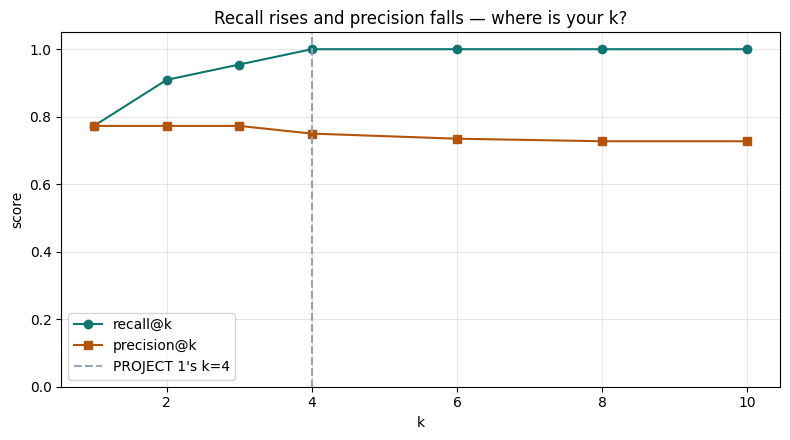


Read the recall curve: the k where it flattens is the k you want.
Everything to the right of that is tokens spent on context that adds nothing.


In [22]:
# --- Sweep k and watch the two metrics diverge ---
cutoff_values = [1, 2, 3, 4, 6, 8, 10]
sweep_rows = []

for cutoff in cutoff_values:
    sweep_retriever = deduplicated_vectorstore.as_retriever(
        search_kwargs={"k": cutoff})
    sweep_results = evaluate_retrieval(GOLDEN_DATASET, sweep_retriever, cutoff=cutoff)
    sweep_rows.append({
        "cutoff": cutoff,
        "recall": statistics.mean(row["recall"] for row in sweep_results),
        "precision": statistics.mean(row["precision"] for row in sweep_results),
    })
    print(f"k={cutoff:<3} recall={sweep_rows[-1]['recall']:.3f}  "
          f"precision={sweep_rows[-1]['precision']:.3f}")

figure, axis = plt.subplots(figsize=(8, 4.5))
axis.plot([row["cutoff"] for row in sweep_rows],
          [row["recall"] for row in sweep_rows],
          marker="o", label="recall@k", color="#0F766E")
axis.plot([row["cutoff"] for row in sweep_rows],
          [row["precision"] for row in sweep_rows],
          marker="s", label="precision@k", color="#B45309")
axis.axvline(4, linestyle="--", color="#94A3B8", label="PROJECT 1's k=4")
axis.set_xlabel("k")
axis.set_ylabel("score")
axis.set_title("Recall rises and precision falls — where is your k?")
axis.set_ylim(0, 1.05)
axis.legend()
axis.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nRead the recall curve: the k where it flattens is the k you want.")
print("Everything to the right of that is tokens spent on context that adds nothing.")


---

# Part C — Generation Metrics

## 11. Faithfulness Is Not a Mystery

Retrieval metrics need no model. Generation metrics do — you cannot check "is this answer
supported by that context" with arithmetic.

That is exactly where people reach for a framework, and exactly where they should not. Here is
the entire faithfulness algorithm, as defined:

1. **Decompose** the answer into atomic statements — one assertion each.
2. **Judge** each statement: is it supported by the retrieved context? Yes or no.
3. **Score** = supported ÷ total.

That is two prompts. Writing them out instead of importing them buys three things:

- **You can read the judge prompt**, so you can fix it when it misjudges your domain — and here
  the domain is investment-policy language, where "should" and "must" are not synonyms.
- **You choose the judge model.** PROJECT 1 runs on OpenAI, so the judge is Claude. With a
  framework the judge is whatever the library was handed, and the family-mismatch rule from
  Lab 5.3 quietly stops being enforced.
- **It is the transferable idea.** "Faithfulness is claim decomposition plus per-claim entailment"
  survives every library you will ever switch to.


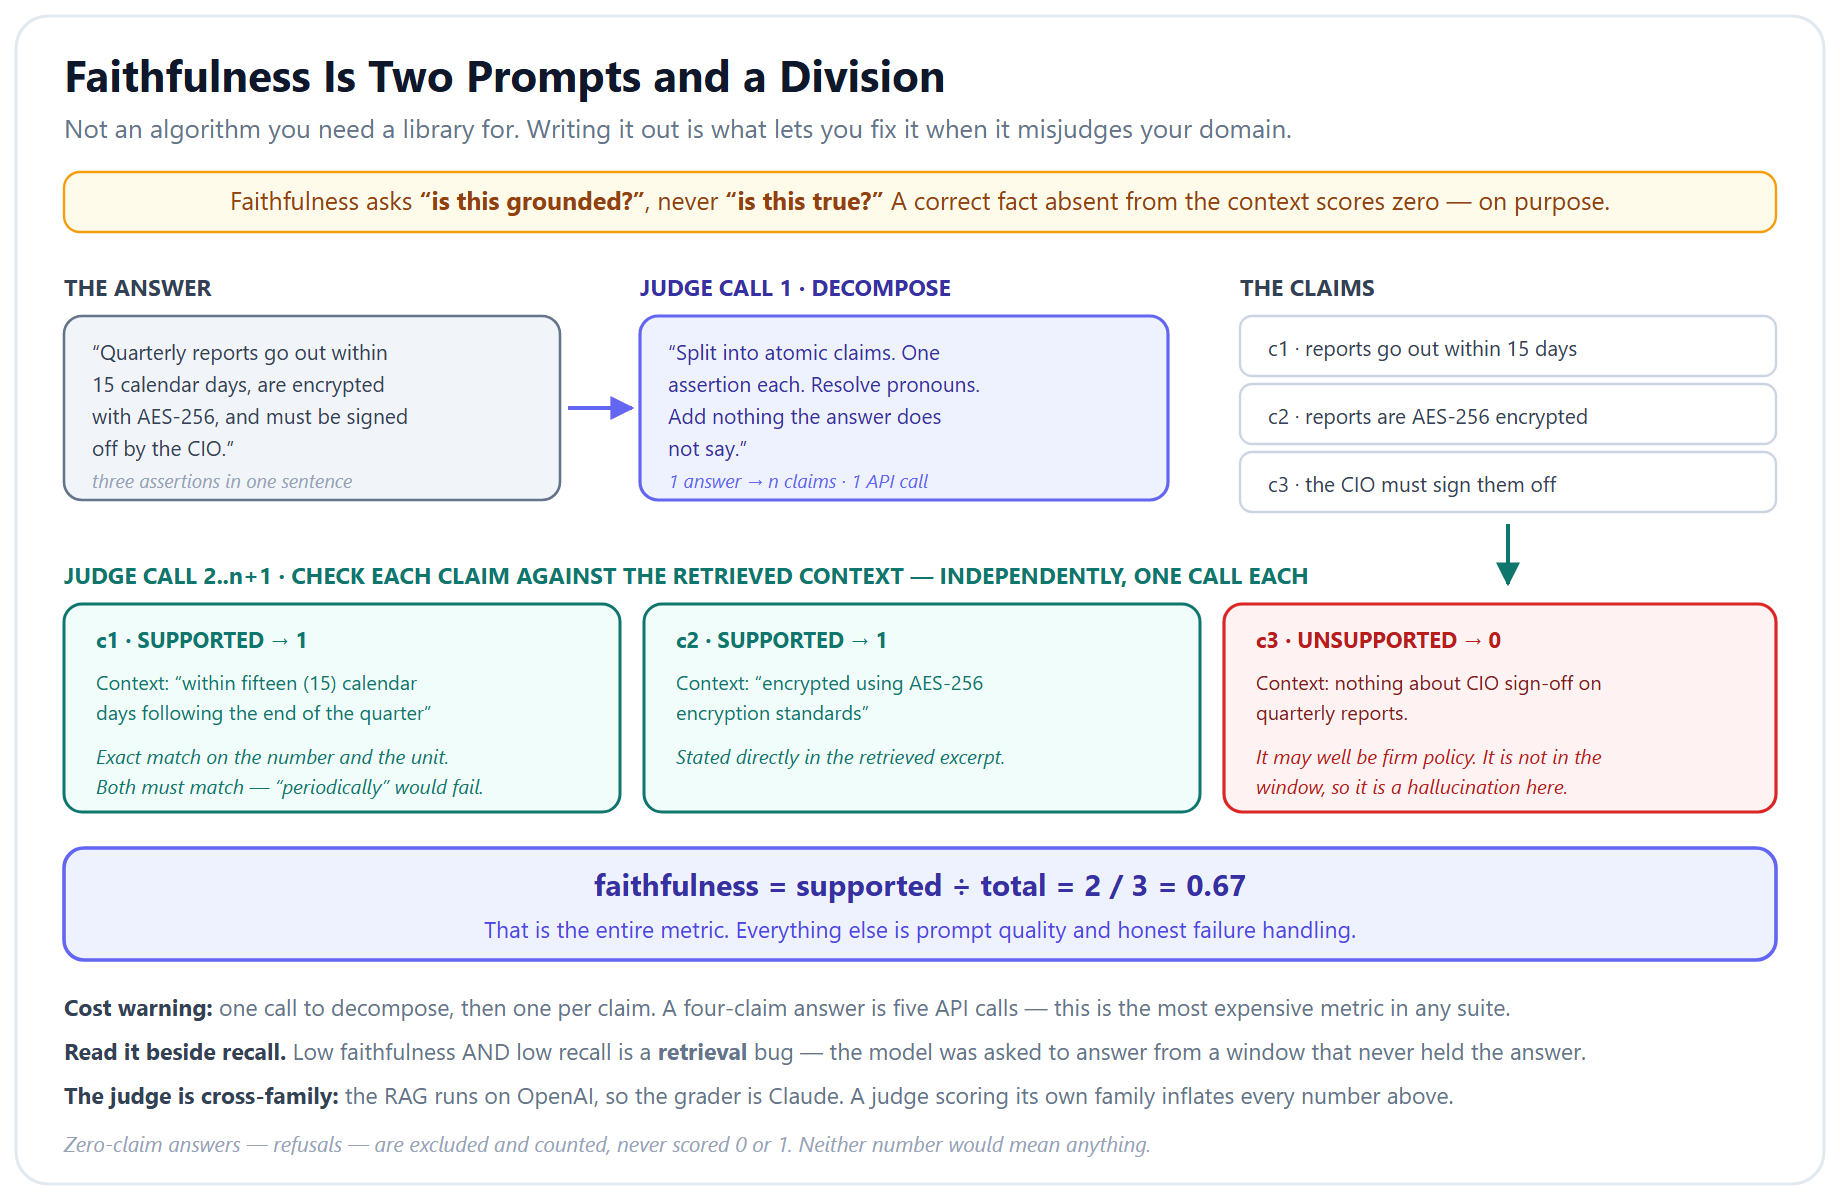

**Figure — Faithfulness, decomposed.** The answer is split into atomic claims, each claim is checked against the retrieved context on its own, and the score is simply supported ÷ total. Two prompts and a division. The value of writing it out rather than importing it is that both prompts are yours to read, edit and fix when they misjudge your domain.

In [23]:
# --- Prompt 1 of 2: decompose an answer into atomic claims ---

CLAIM_DECOMPOSITION_PROMPT = ChatPromptTemplate.from_messages([
    ("system", """You break an answer into atomic factual claims so each one can be checked
separately.

Rules:
1. Each claim states EXACTLY ONE assertion. Split any sentence that asserts two things.
2. Each claim must stand alone. Replace pronouns and references with the thing they refer to,
   so "it must be reviewed quarterly" becomes "the portfolio must be reviewed quarterly".
3. Use ONLY what the answer says. Never add, infer or complete anything, even if you are
   confident it is true.
4. Do not restate the same assertion twice in different words.
5. Ignore hedging and framing ("based on the excerpts", "I think") — extract the assertion.
6. If the answer makes no factual assertion at all — a refusal, or "the excerpts do not cover
   this" — return an empty list.

Return ONLY a JSON object, no prose and no code fence:
{{"claims": ["first claim", "second claim"]}}"""),
    ("human", "ANSWER:\n{answer}"),
])

claim_decomposition_chain = (
    CLAIM_DECOMPOSITION_PROMPT | judge_model | StrOutputParser()
)


# --- Prompt 2 of 2: is one claim supported by the retrieved context? ---

CLAIM_ENTAILMENT_PROMPT = ChatPromptTemplate.from_messages([
    ("system", """You decide whether a single claim is supported by the provided context.

Answer 1 only if the context states or directly entails the claim. Answer 0 otherwise.

Judge strictly, because these are policy documents:
- A claim that is true in general but absent from the context is 0. You are checking grounding,
  not correctness.
- Numbers, thresholds and timeframes must match exactly. "Reviewed quarterly" is NOT supported by
  context saying "reviewed periodically", and 15% is not supported by "up to 20%".
- "Must" is not supported by context that says "should" or "may", and vice versa.
- Partial support is 0. If half the claim is in the context and half is not, it is unsupported.

Return ONLY a JSON object, no prose and no code fence:
{{"verdict": 1, "reason": "one short sentence"}}"""),
    ("human", "CONTEXT:\n{context}\n\nCLAIM:\n{claim}"),
])

claim_entailment_chain = (
    CLAIM_ENTAILMENT_PROMPT | judge_model | StrOutputParser()
)

print("Two judge chains built, both ChatPromptTemplate | judge_model | StrOutputParser().")
print("StrOutputParser, not a JSON parser, is deliberate: this lab needs to SEE malformed")
print("judge output and record it as a failure, not have a parser quietly repair it.")

Two judge chains built, both ChatPromptTemplate | judge_model | StrOutputParser().
StrOutputParser, not a JSON parser, is deliberate: this lab needs to SEE malformed
judge output and record it as a failure, not have a parser quietly repair it.


### Calling a judge without lying to yourself

The judge is an LLM, so it will sometimes return something unusable. There are exactly two honest
ways to handle that: retry it, or record the row as unscored and exclude it. There is a third,
dishonest way — substitute a default score — and it is the most common. A judge that fails on 8
of 20 rows and quietly scores them 0.5 produces a dashboard that looks fine and means nothing.

Three details below are worth more than they look:

- **Only transient errors are retried.** Catching bare `Exception` means a typo in your own
  prompt-input keys gets reported as "the judge failed", and you debug the wrong system.
- **Retries back off.** The usual transient failure is a rate limit; an instant retry hits the
  same limit and burns the retry budget without ever helping.
- **Exclusions are counted and reported by reason.** Never folded into the mean.


In [24]:
# --- Invoking a judge chain, honestly ---
import time

from anthropic import APIConnectionError, APIError, APITimeoutError, RateLimitError

# Only these are worth retrying. Anything else — a KeyError from a mistyped prompt variable,
# an ImportError, a bug in our own code — must propagate, loudly, as the bug it is.
RETRYABLE_JUDGE_ERRORS = (APIConnectionError, APITimeoutError, RateLimitError, APIError)
RETRY_BACKOFF_SECONDS = 2.0


class JudgeFailure(Exception):
    """Raised when the judge answered, but not with something we can use."""


def parse_judge_json(raw_response):
    """Parse a judge response into a dict, tolerating a markdown code fence.

    Args:
        raw_response: the judge's raw text.

    Returns:
        The parsed object.

    Raises:
        JudgeFailure: if the text is not a JSON object.
    """
    cleaned_text = raw_response.strip()
    if cleaned_text.startswith("```"):
        cleaned_text = cleaned_text.split("```")[1]
        if cleaned_text.startswith("json"):
            cleaned_text = cleaned_text[4:]
        cleaned_text = cleaned_text.strip()
    try:
        parsed_object = json.loads(cleaned_text)
    except json.JSONDecodeError as parse_error:
        raise JudgeFailure(f"response was not JSON: {parse_error}") from parse_error
    if not isinstance(parsed_object, dict):
        raise JudgeFailure(f"expected a JSON object, got {type(parsed_object).__name__}")
    return parsed_object


def invoke_judge(judge_chain, chain_inputs, attempt_limit=3):
    """Invoke a judge chain and parse its JSON reply, retrying transient failures.

    Args:
        judge_chain: a `prompt | judge_model | StrOutputParser()` runnable.
        chain_inputs: the dict of prompt variables.
        attempt_limit: how many times to try before giving up.

    Returns:
        The parsed JSON object.

    Raises:
        JudgeFailure: if every attempt failed. The caller records this and excludes the row.
    """
    last_problem = None
    for attempt_number in range(1, attempt_limit + 1):
        if attempt_number > 1:
            # Back off: the usual transient failure is a rate limit, and retrying instantly
            # just hits it again.
            time.sleep(RETRY_BACKOFF_SECONDS * (attempt_number - 1))
        try:
            return parse_judge_json(judge_chain.invoke(chain_inputs))
        except RETRYABLE_JUDGE_ERRORS as call_error:
            last_problem = f"{type(call_error).__name__}: {call_error}"
        except JudgeFailure as format_error:
            last_problem = str(format_error)
    raise JudgeFailure(f"gave up after {attempt_limit} attempts — {last_problem}")

### Validate what the judge sent back

Every check below exists because the corresponding mistake produces a **wrong number rather than
an error**, which is the only kind of bug an evaluation harness cannot survive:

| Check | What it catches | What happens without it |
|---|---|---|
| Claims are a list of **strings** | `{"claims": [{"claim": "…"}]}` | The stringified dict `"{'claim': …}"` is sent to the entailment judge and scored |
| Verdict is an **int**, 0 or 1 | `True`, `1.0`, `"1"` | In Python `True == 1`, so a naive membership test lets booleans and floats through |
| `noncommittal` is a **real bool** | `{"noncommittal": "false"}` | Every non-empty string is truthy, so `"false"` scores the answer **0.0** |

That last one is the sharpest. A quoted boolean is among the most common malformed replies an LLM
judge produces, and truth-testing it turns a good answer into a zero silently.


In [25]:
# --- Metric 1: faithfulness = supported claims / total claims ---

def decompose_answer_into_claims(answer_text):
    """Split an answer into atomic factual claims.

    Args:
        answer_text: the generated answer.

    Returns:
        A list of claim strings, possibly empty when the answer asserts nothing.

    Raises:
        JudgeFailure: if the judge's reply is not a list of strings.
    """
    parsed_object = invoke_judge(claim_decomposition_chain, {"answer": answer_text})
    raw_claims = parsed_object.get("claims")
    if not isinstance(raw_claims, list):
        raise JudgeFailure(
            f"'claims' must be a list, got {type(raw_claims).__name__}")
    if not all(isinstance(claim, str) for claim in raw_claims):
        offending_types = [type(claim).__name__ for claim in raw_claims]
        raise JudgeFailure(f"'claims' must be a list of strings, got {offending_types}")
    return [claim.strip() for claim in raw_claims if claim.strip()]


def judge_claim_support(claim_text, context_text):
    """Decide whether one claim is supported by the retrieved context.

    Returns:
        True if supported, False otherwise.

    Raises:
        JudgeFailure: if the verdict is missing or is not the integer 0 or 1.
    """
    parsed_object = invoke_judge(
        claim_entailment_chain, {"claim": claim_text, "context": context_text})
    raw_verdict = parsed_object.get("verdict")
    # `isinstance(True, int)` is True in Python, so booleans must be excluded explicitly —
    # otherwise `{"verdict": true}` silently counts as a supported claim.
    is_valid_verdict = (isinstance(raw_verdict, int)
                        and not isinstance(raw_verdict, bool)
                        and raw_verdict in (0, 1))
    if not is_valid_verdict:
        raise JudgeFailure(f"verdict must be the integer 0 or 1, got {raw_verdict!r}")
    return raw_verdict == 1


def score_faithfulness(answer_text, context_text):
    """Score how much of an answer is grounded in its retrieved context.

    Args:
        answer_text: the generated answer.
        context_text: the formatted retrieved excerpts it should be grounded in.

    Returns:
        A dict with `status` ("scored" or "judge_failed"), `score`, `claim_count`,
        `supported_count` and `failure_reason`. A failed row is never given a default score.
    """
    try:
        claims = decompose_answer_into_claims(answer_text)
    except JudgeFailure as decomposition_error:
        return {"status": "judge_failed", "score": None, "claim_count": 0,
                "supported_count": 0, "failure_reason": str(decomposition_error)}

    if not claims:
        # A refusal asserts nothing, so nothing can be unsupported. Scoring it 1.0 would reward
        # a system for declining to answer; scoring it 0.0 would punish an honest refusal.
        # Neither is meaningful, so it is excluded and counted.
        return {"status": "no_claims", "score": None, "claim_count": 0,
                "supported_count": 0,
                "failure_reason": "answer made no factual assertion"}

    supported_count = 0
    for claim_text in claims:
        try:
            if judge_claim_support(claim_text, context_text):
                supported_count += 1
        except JudgeFailure as entailment_error:
            return {"status": "judge_failed", "score": None,
                    "claim_count": len(claims), "supported_count": supported_count,
                    "failure_reason": str(entailment_error)}

    return {"status": "scored", "score": supported_count / len(claims),
            "claim_count": len(claims), "supported_count": supported_count,
            "failure_reason": ""}

In [26]:
# --- Metric 2: answer relevancy = does the answer address the question asked? ---

ANSWER_RELEVANCY_PROMPT = ChatPromptTemplate.from_messages([
    ("system", """You rate how well an answer addresses the question that was asked.

Rate ONLY relevance to the question. Do NOT rate whether the answer is factually correct, and do
NOT rate how well written it is — faithfulness is measured separately.

Scale:
5 — answers exactly what was asked, completely
4 — answers what was asked, with a minor gap
3 — partially answers it, or answers a narrower question than the one asked
2 — related to the topic but does not answer the question
1 — off topic

Set "noncommittal" to true if the answer declines to answer, says it does not know, or says the
information was not available. A noncommittal answer scores 0 regardless of its rating.

Return ONLY a JSON object, no prose and no code fence:
{{"rating": 4, "noncommittal": false, "reason": "one short sentence"}}"""),
    ("human", "QUESTION:\n{question}\n\nANSWER:\n{answer}"),
])

answer_relevancy_chain = (
    ANSWER_RELEVANCY_PROMPT | judge_model | StrOutputParser()
)


def score_answer_relevancy(question_text, answer_text):
    """Score whether an answer addresses the question, independent of correctness.

    Args:
        question_text: the question that was asked.
        answer_text: the generated answer.

    Returns:
        A dict with `status`, `score` (0.0-1.0), `rating` (1-5), `noncommittal` and
        `failure_reason`.
    """
    try:
        parsed_object = invoke_judge(
            answer_relevancy_chain,
            {"question": question_text, "answer": answer_text})
    except JudgeFailure as judge_error:
        return {"status": "judge_failed", "score": None, "rating": None,
                "noncommittal": None, "failure_reason": str(judge_error)}

    raw_rating = parsed_object.get("rating")
    is_valid_rating = (isinstance(raw_rating, int)
                       and not isinstance(raw_rating, bool)
                       and 1 <= raw_rating <= 5)
    if not is_valid_rating:
        return {"status": "judge_failed", "score": None, "rating": None,
                "noncommittal": None,
                "failure_reason": f"rating must be an integer 1-5, got {raw_rating!r}"}

    # Validate rather than truth-test. `bool("false")` is True, so a quoted boolean would
    # silently zero a perfectly good answer — the one path where a malformed judge reply
    # becomes a number instead of an exclusion.
    raw_noncommittal = parsed_object.get("noncommittal", False)
    if not isinstance(raw_noncommittal, bool):
        return {"status": "judge_failed", "score": None, "rating": None,
                "noncommittal": None,
                "failure_reason":
                    f"noncommittal must be a boolean, got {raw_noncommittal!r}"}

    relevancy_score = 0.0 if raw_noncommittal else (raw_rating - 1) / 4.0
    return {"status": "scored", "score": relevancy_score, "rating": raw_rating,
            "noncommittal": raw_noncommittal, "failure_reason": ""}

In [27]:
# --- Aggregating judged results without hiding the exclusions ---

def summarise_judged_metric(row_results, metric_name):
    """Average the scored rows and report every excluded row by reason.

    Each row is classified exactly once, so the exclusion count can never disagree with the
    reasons that explain it.

    Args:
        row_results: the per-row dicts returned by a scorer.
        metric_name: label for the printed summary.

    Returns:
        A dict with `mean_score`, `scored_count`, `excluded_count` and `exclusion_reasons`.
    """
    scored_values = []
    exclusion_reasons = {}
    for row_result in row_results:
        if row_result["status"] == "scored" and row_result["score"] is not None:
            scored_values.append(row_result["score"])
        else:
            reason = row_result["status"]
            exclusion_reasons[reason] = exclusion_reasons.get(reason, 0) + 1

    mean_score = statistics.mean(scored_values) if scored_values else None
    summary = {"mean_score": mean_score, "scored_count": len(scored_values),
               "excluded_count": len(row_results) - len(scored_values),
               "exclusion_reasons": exclusion_reasons}

    printed_mean = "n/a" if mean_score is None else f"{mean_score:.3f}"
    print(f"{metric_name}: {printed_mean}  "
          f"({summary['scored_count']} scored, {summary['excluded_count']} excluded)")
    for reason, count in sorted(exclusion_reasons.items()):
        print(f"    excluded — {reason}: {count}")
    if summary["scored_count"] < len(row_results) * 0.8:
        print("    ⚠️  More than a fifth of rows were excluded. Fix that before trusting "
              "this number.")
    return summary


## 12. Run Both Generation Metrics

A warning about cost before you run this. Faithfulness is **one judge call per claim**, plus one
to decompose. A four-claim answer is five calls, so twenty-two questions is well over a hundred —
and that is the cheapest possible version of this metric.

This is not a footnote. A faithfulness suite is by far the most expensive thing in an eval
pipeline, and teams discover that after wiring it into CI on every commit. Budget for it, sample
deliberately, and run the full set on a schedule rather than on every push.

We score **eight** questions here for exactly that reason. Eight is too few to publish. It is
enough to see the machinery work and to calibrate it in section 13, which is what we need.


In [28]:
# --- Score faithfulness and answer relevancy on a deliberate subset ---
GENERATION_SAMPLE_SIZE = 22
# generation_sample = GOLDEN_DATASET[:GENERATION_SAMPLE_SIZE]

generation_sample = GOLDEN_DATASET[:]
faithfulness_rows = []
relevancy_rows = []
generated_answers = []

print(f"Scoring {GENERATION_SAMPLE_SIZE} questions — expect ~40 judge calls.\n")

for entry in generation_sample:
    pipeline_result = rag_pipeline.invoke(entry["question"])
    context_text = format_documents_for_prompt(pipeline_result["retrieved_documents"])
    answer_text = pipeline_result["answer"]
    generated_answers.append({
        "question_id": entry["question_id"],
        "question": entry["question"],
        "answer": answer_text,
        "context": context_text,
        "reference_answer": entry["reference_answer"],
    })

    faithfulness_result = score_faithfulness(answer_text, context_text)
    faithfulness_result["question_id"] = entry["question_id"]
    faithfulness_rows.append(faithfulness_result)

    relevancy_result = score_answer_relevancy(entry["question"], answer_text)
    relevancy_result["question_id"] = entry["question_id"]
    relevancy_rows.append(relevancy_result)

    faithfulness_display = ("--" if faithfulness_result["score"] is None
                            else f"{faithfulness_result['score']:.2f}")
    relevancy_display = ("--" if relevancy_result["score"] is None
                         else f"{relevancy_result['score']:.2f}")
    print(f"   {entry['question_id']}  faithfulness={faithfulness_display}  "
          f"({faithfulness_result['supported_count']}/"
          f"{faithfulness_result['claim_count']} claims)  "
          f"relevancy={relevancy_display}")

print()
faithfulness_summary = summarise_judged_metric(faithfulness_rows, "faithfulness")
print()
relevancy_summary = summarise_judged_metric(relevancy_rows, "answer relevancy")

Scoring 22 questions — expect ~40 judge calls.

   Q01  faithfulness=0.00  (0/1 claims)  relevancy=0.75
   Q02  faithfulness=0.50  (3/6 claims)  relevancy=0.25
   Q03  faithfulness=0.75  (3/4 claims)  relevancy=1.00
   Q04  faithfulness=1.00  (6/6 claims)  relevancy=0.75
   Q05  faithfulness=--  (0/0 claims)  relevancy=--
   Q06  faithfulness=0.75  (3/4 claims)  relevancy=0.50
   Q07  faithfulness=1.00  (2/2 claims)  relevancy=1.00
   Q08  faithfulness=0.75  (3/4 claims)  relevancy=0.75
   Q09  faithfulness=--  (0/0 claims)  relevancy=--
   Q10  faithfulness=1.00  (4/4 claims)  relevancy=1.00
   Q11  faithfulness=0.80  (4/5 claims)  relevancy=0.75
   Q12  faithfulness=1.00  (6/6 claims)  relevancy=1.00
   Q13  faithfulness=1.00  (2/2 claims)  relevancy=0.25
   Q14  faithfulness=0.50  (2/4 claims)  relevancy=1.00
   Q15  faithfulness=1.00  (4/4 claims)  relevancy=1.00
   Q16  faithfulness=1.00  (3/3 claims)  relevancy=1.00
   Q17  faithfulness=1.00  (3/3 claims)  relevancy=0.00
   Q18  

### What a low faithfulness score is usually telling you

The instinct is to tighten the answer prompt. Check the other explanation first.

| Faithfulness | Recall for the same question | The real problem |
|---|---|---|
| Low | **Low** | **Retrieval.** The model was asked a question whose answer was never in the window, and it filled the gap. The prompt is not the bug |
| Low | High | **Generation.** The context was right there and the answer still drifted. Now tighten the prompt |
| High | Low | The model correctly refused, or answered only the part it could support. This is the system behaving well under a retrieval failure |

That first row is why this lab measures retrieval before generation, and why the two must be read
together. A faithfulness dashboard on its own will send you to fix the wrong system.


In [29]:
# --- Join the two layers: which failure is which? ---
retrieval_by_question = {row["question_id"]: row for row in baseline_results}

print(f"{'id':<5} {'recall@4':>9} {'faithful':>9}   diagnosis")
print("-" * 74)
for faithfulness_result in faithfulness_rows:
    question_id = faithfulness_result["question_id"]
    recall_value = retrieval_by_question[question_id]["recall"]
    faithfulness_value = faithfulness_result["score"]

    if faithfulness_value is None:
        diagnosis = f"not scored — {faithfulness_result['status']}"
    elif faithfulness_value < 0.7 and recall_value == 0.0:
        diagnosis = "RETRIEVAL — the answer was never in the window"
    elif faithfulness_value < 0.7:
        diagnosis = "GENERATION — context was present, answer drifted"
    elif recall_value == 0.0:
        diagnosis = "handled well — refused or hedged despite a retrieval miss"
    else:
        diagnosis = "healthy"

    faithfulness_display = ("  --" if faithfulness_value is None
                            else f"{faithfulness_value:.2f}")
    print(f"{question_id:<5} {recall_value:>9.2f} {faithfulness_display:>9}   {diagnosis}")

id     recall@4  faithful   diagnosis
--------------------------------------------------------------------------
Q01        1.00      0.00   GENERATION — context was present, answer drifted
Q02        1.00      0.50   GENERATION — context was present, answer drifted
Q03        1.00      0.75   healthy
Q04        1.00      1.00   healthy
Q05        1.00        --   not scored — no_claims
Q06        1.00      0.75   healthy
Q07        1.00      1.00   healthy
Q08        1.00      0.75   healthy
Q09        1.00        --   not scored — no_claims
Q10        1.00      1.00   healthy
Q11        1.00      0.80   healthy
Q12        1.00      1.00   healthy
Q13        1.00      1.00   healthy
Q14        1.00      0.50   GENERATION — context was present, answer drifted
Q15        1.00      1.00   healthy
Q16        1.00      1.00   healthy
Q17        1.00      1.00   healthy
Q18        1.00      1.00   healthy
Q19        1.00        --   not scored — no_claims
Q20        1.00      1.00   healthy


---

# Part D — The Part That Matters

## 13. Your Graders Are Systems Under Test Too

Everything above produced numbers. **Nobody has checked whether any of them are right.**

This is the strongest argument for owning your metrics, and it is worth stating plainly: a custom
metric that is subtly wrong is *worse* than a library one, because no one else will ever catch
it. There is no community, no issue tracker, no other team hitting the same bug. The only defence
is to measure the grader against something outside itself.

That something is **you**. Hand-label a sample, compare, and report the agreement.

> **The threshold: 80%.** Below roughly 80% agreement with human labels, **fix the grader, not
> the RAG system.** Every number on your dashboard came from an instrument, and an instrument
> nobody calibrated is a decoration.

Lab 5.3 measured a judge with two numbers, and both are needed here:

- **Mean signed error** — is the grader systematically generous or harsh? That is **bias**, and a
  biased grader still ranks candidates correctly. Its absolute numbers are wrong; its comparisons
  are fine.
- **Mean absolute error** — how far off is it on a *typical* row? That is **noise**, and a noisy
  grader cannot rank anything, no matter how good its average looks.

A grader that scores half the rows +3 too high and half −3 too low has a mean signed error of 0
and looks perfectly calibrated. Only the absolute error exposes it.


In [30]:
# --- Calibrating a grader against human labels ---

def calibrate_grader(grader_scores, human_scores):
    """Compare grader output against human labels and report bias, noise and agreement.

    Args:
        grader_scores: the grader's score per sampled row, in [0.0, 1.0].
        human_scores: your own label for the same rows, in [0.0, 1.0], assigned WITHOUT
            looking at the grader's answer.

    Returns:
        A dict with `mean_signed_error` (bias), `mean_absolute_error` (noise),
        `agreement_rate` (fraction within the tolerance) and `sample_size`.

    Raises:
        ValueError: if the two lists are not the same length, or are empty.
    """
    if len(grader_scores) != len(human_scores):
        raise ValueError(
            f"need one human label per grader score, got "
            f"{len(grader_scores)} and {len(human_scores)}")
    if not grader_scores:
        raise ValueError("cannot calibrate on an empty sample")

    # Two rows agree when they land within this much of each other. On a 0-1 scale, 0.2 is one
    # step of a five-point rubric — close enough to be the same judgement.
    agreement_tolerance = 0.2

    signed_errors = [grader - human
                     for grader, human in zip(grader_scores, human_scores)]
    absolute_errors = [abs(error) for error in signed_errors]
    agreeing_rows = sum(1 for error in absolute_errors
                        if error <= agreement_tolerance)

    return {
        "mean_signed_error": statistics.mean(signed_errors),
        "mean_absolute_error": statistics.mean(absolute_errors),
        "agreement_rate": agreeing_rows / len(grader_scores),
        "sample_size": len(grader_scores),
    }


def report_calibration(calibration, grader_name):
    """Print a calibration result and say what to do about it."""
    print(f"— calibration: {grader_name} (n={calibration['sample_size']}) —")
    print(f"   mean signed error  : {calibration['mean_signed_error']:+.3f}   (bias)")
    print(f"   mean absolute error: {calibration['mean_absolute_error']:.3f}    (noise)")
    print(f"   agreement rate     : {calibration['agreement_rate']:.0%}")

    if calibration["agreement_rate"] < 0.8:
        print("   ❌ Below 80%. FIX THE GRADER — its prompt, not your RAG system.")
    elif abs(calibration["mean_signed_error"]) > 0.15:
        direction = "generous" if calibration["mean_signed_error"] > 0 else "harsh"
        print(f"   ⚠️  Usable for ranking, but systematically {direction} — do not quote "
              "the absolute numbers.")
    else:
        print("   ✅ Calibrated. Act on this dashboard.")
    return calibration


# --- A worked demonstration: the two failure modes, side by side ---
human_labels = [1.0, 0.75, 0.5, 1.0, 0.25, 0.75, 1.0, 0.5]

biased_grader = [score + 0.2 if score <= 0.8 else score for score in human_labels]
noisy_grader = [1.0, 0.25, 1.0, 0.5, 0.75, 0.25, 0.5, 1.0]

report_calibration(calibrate_grader(human_labels, human_labels), "a perfect grader")
print()
report_calibration(calibrate_grader(biased_grader, human_labels), "a BIASED grader")
print()
report_calibration(calibrate_grader(noisy_grader, human_labels), "a NOISY grader")
print()
print("Look at the noisy grader's signed error. It is tiny — the errors cancel.")
print("Averaging hides scatter. Only the absolute error tells you it cannot rank anything.")

— calibration: a perfect grader (n=8) —
   mean signed error  : +0.000   (bias)
   mean absolute error: 0.000    (noise)
   agreement rate     : 100%
   ✅ Calibrated. Act on this dashboard.

— calibration: a BIASED grader (n=8) —
   mean signed error  : +0.125   (bias)
   mean absolute error: 0.125    (noise)
   agreement rate     : 100%
   ✅ Calibrated. Act on this dashboard.

— calibration: a NOISY grader (n=8) —
   mean signed error  : -0.062   (bias)
   mean absolute error: 0.438    (noise)
   agreement rate     : 12%
   ❌ Below 80%. FIX THE GRADER — its prompt, not your RAG system.

Look at the noisy grader's signed error. It is tiny — the errors cancel.
Averaging hides scatter. Only the absolute error tells you it cannot rank anything.



---

## 14. Deep dive — the five ways an LLM judge misleads you

*Self-paced. Everything above already works.*

Calibration tells you *that* a judge is wrong. These five tell you *why*, and each has a specific
countermeasure. Four of them are already built into this notebook.

| Bias | What it looks like | Countermeasure | Where |
|---|---|---|---|
| **Self-preference** | The judge scores text from its own model family higher | Judge from a different family | `judge_model` is Anthropic, the system is OpenAI |
| **Position** | Whichever candidate is shown first wins | Score candidates independently, or swap order and average | Our graders score one answer at a time |
| **Verbosity** | Longer answers score higher regardless of content | Rubrics that name what to look for; length-controlled comparisons | The relevancy rubric rates *coverage*, not length |
| **Format** | Confident tone, headings and bullets score higher than plain prose | Grade claims, not presentation | Faithfulness decomposes into claims first |
| **Calibration drift** | The same judge scores differently as the provider updates the model | Re-calibrate on a schedule; pin the judge model | `claude-haiku-4-5` is pinned, and section 13 is repeatable |

**Self-preference is the one that will actually bite you**, because it is invisible: the judge
does not know it is doing it, and the scores look reasonable. The fix costs one line and one extra API key.

**Verbosity bias has a nastier second-order effect.** If you optimise your prompts against a
verbosity-biased judge, you will systematically evolve a more verbose system — the judge rewards
padding, so your optimiser produces padding. You will have automated your way to a worse product
while every number improved.



## 15. Deep dive — so should you ever use a framework?

*Self-paced.*

This lab implemented its metrics. That was a deliberate choice, not a dogma, and it costs you
three real things. Here they are, honestly, with what to do about each.

| What you give up | Why it hurts | What to do instead |
|---|---|---|
| **Comparability** | "Our faithfulness is 0.85" no longer means what a paper means by it | Document the prompt and the formula next to the number. For production work, your own trend over time beats external comparability anyway |
| **Community scrutiny** | Nobody else will ever find your bug | Section 13. Calibrate against human labels, on a schedule |
| **Free synthetic test sets** | You write the golden dataset yourself | Generate candidates with a documented LLM call, then **human-review every one**. You should be doing this even with a framework — synthetic-only test sets flatter the system that generated them |

**And if you do want a framework, it should probably be DeepEval, not RAGAS.** Apache-2.0,
testing-first, plugs straight into `pytest` — which lines up exactly with the CI gate you built in
Lab 5.3 — and it covers agents, multi-turn and safety, not just RAG's four metrics. It is still a
vendor-backed product with its own churn risk, which is why this lab does not import it.

**The honest summary.** Use a framework to *run* an eval suite at scale. Do not use one to *learn*
what the numbers mean, and do not use one for a metric as easy to write as `recall@k` — that is
taking a dependency on arithmetic.

Notice which half of this lab actually needed judgement. The four retrieval metrics are about
sixty lines of arithmetic that will never drift. The two generation metrics are two prompts. The
part that took real work — and the part a framework will never do for you — was the **golden
dataset** and the **calibration**.



## 16. From lab to production

*Self-paced.*

Everything above runs. Here is the honest gap list between it and something you would gate a
deployment on — each item is either yours to add today, or something your production stack
will need to own.

*Several of the rows below are the same problem in different clothes — cost accounting, structured failure records, versioned configuration, dataset versioning. Teams running more than one agent usually end up factoring those into a shared internal library rather than rebuilding them per service. This programme does not ship one; being able to name what would belong in it is the point.*

| Gap in this notebook | What production needs | Where it lands |
|---|---|---|
| 24 questions, hand-written | 50–200 drawn from real traffic, versioned alongside the prompt and the index | Your production stack |
| Relevance labelled at document level | Chunk-level labels, so `precision@k` measures context quality directly | Your production stack |
| One calibration run, by hand | Scheduled re-calibration with an alert when agreement drops below 80% | Your production stack |
| Judge failures print a reason | Structured failure records and a judge failure-rate metric | Your production stack |
| Eval cost is untracked | Tokens and spend per eval run — a faithfulness suite is one LLM call *per claim*, and that adds up fast | Your production stack |
| Results print to stdout | Persisted per commit, so you can watch a metric move over releases | Your production stack |
| The suite runs when you run it | A CI gate with per-metric thresholds — Lab 5.3 builds the harness | Lab 5.3 |
| Retrieval is evaluated once | Re-run on every chunking, embedding, index or prompt change | You, today |

**If you take one thing from this lab:** the metric is the easy part. Sixty lines of arithmetic
and two prompts. The hard parts are deciding what "relevant" means and writing it down, and
proving your grader agrees with a human. No library does either for you, and no dashboard is worth
anything until both are done.



---

## Conclusion

We evaluated PROJECT 1's RAG system end to end, with metrics we wrote and checked:

| Layer | Metric | What it caught |
|---|---|---|
| **Retrieval** | `recall@k` | Whether the answering document was found at all — the unrecoverable failure |
| | `precision@k` | How much of the context window was earned |
| | `MRR` | How far down the first useful hit was |
| | `nDCG@k` | Whether the *ordering* is good, under graded relevance |
| **Generation** | Faithfulness | Claims not supported by the retrieved context |
| | Answer relevancy | Answers that address a different question than the one asked |
| **The grader** | Calibration | Whether any of the above can be believed |

Three things worth carrying out of here:

1. **Retrieval failure is unrecoverable; generation failure is not.** No prompt fixes a document
   that was never retrieved. That is why `recall@k` is the gate.
2. **Faithfulness is claim decomposition plus per-claim entailment.** That sentence survives every
   library you will ever switch to.
3. **An uncalibrated grader is a decoration.** Below 80% agreement with a human, fix the grader.

### Next Lab Preview

Module 5 measured things. **Module 6 defends them.** Its guardrails lab builds a layered guardrail system —
input sanitisation, prompt-injection defence, output validation and PII protection — around the
same ShopSmart agent, and its observability lab makes the whole thing observable so you can see what happened
when it happens in production rather than reconstructing it afterwards.

The connection is closer than it looks: a guardrail is a grader that runs in the request path. You
already know how to tell whether one works.



## Further reading

**Start here — the two that shaped this lab**
- [RAGAS faithfulness metric definition](https://docs.ragas.io/en/stable/concepts/metrics/available_metrics/faithfulness/) — the claim-decomposition algorithm, documented. We implemented it rather than importing it, but this is where the definition lives.
- [Retrieval evaluation metrics](https://www.dataaihub.co/learn/retrieval-evaluation) — recall / precision / MRR / nDCG with worked examples.

**The reference implementations**
- [`sklearn.metrics.ndcg_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ndcg_score.html) — the one section 8 checks our nDCG against. Note its **linear** gain convention.
- [DeepEval](https://pypi.org/project/deepeval/) — the framework worth considering if you ever want one. Testing-first, `pytest`-native.

**Going further**
- [RAG evaluation metrics guide](https://slavadubrov.github.io/blog/2026/05/10/rag-evaluation-metrics/) — a broader survey of the metric landscape.
- [RAGAS v0.3 → v0.4 migration guide](https://docs.ragas.io/en/v0.4.0/howtos/migrations/migrate_from_v03_to_v04/) — worth reading as a case study in why pinning a fast-moving eval dependency into teaching material is a liability.
